<a href="https://colab.research.google.com/github/Navneet06dhoni/AI-and-Society-Assignment/blob/main/Navneet_S24CSEU2830_Assignment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Stress-Testing a Predictive Model: COMPAS Recidivism Risk

**Dataset:** ProPublica COMPAS two-year recidivism data
**Models:** Linear regression (OLS) vs. logistic regression, followed by four stress tests
(Simpson's paradox, omitted-variable bias, adversarial subset, fairness trade-off).

**How to use this notebook:** run it from top to bottom (`Runtime > Run all` in Colab).
Every number quoted in the PDF report is computed here and stored in the dictionary `R`.
The last section builds the PDF report automatically from `R`, so numbers in the report
always match the code.

| Section | Content |
|---|---|
| 0 | Configuration and helper functions |
| 1 | Data preprocessing (missing values, encoding, scaling, outliers) |
| 2 | Part 1: linear vs. logistic comparison |
| 3 | Part 2.1: Simpson's paradox hunt |
| 4 | Part 2.2: omitted-variable bias |
| 5 | Part 2.3: adversarial subset |
| 6 | Part 2.4: fairness trade-off |
| 7 | Parts 3-4 and PDF report generation |

## 0. Configuration and helper functions
STUDENT_NAME = "Navneet Krishna"
ROLL_NO = "S24CSEU2830"
SEED = 830

In [1]:
import os, sys, re, math, warnings, subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score
warnings.filterwarnings("ignore")

STUDENT_NAME = "Navneet Krishna"
ROLL_NO = "S24CSU2830"
# --------------------------------
SEED = 830
DATA_URL = "https://github.com/propublica/compas-analysis/raw/master/compas-scores-two-years.csv"
DATA_PATH = os.environ.get("COMPAS_CSV", DATA_URL)   # env var only used for offline testing
OUT = "outputs"; os.makedirs(OUT, exist_ok=True)

GROUP_A, GROUP_B = "Caucasian", "African-American"   # fairness groups (Part 2.4)
DROP_VAR = "priors_count"                              # confounder dropped in Part 2.2
CHOSEN_T = None                                        # None = pick automatically in Part 2.4
THRESHOLDS = np.round(np.arange(0.05, 0.96, 0.10), 2)  # 0.05, 0.15, ..., 0.95
R = {}                                                 # every reported number is stored here
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

In [2]:
def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-np.clip(z, -35, 35)))

def logit_fit(X, y, max_iter=100, tol=1e-9):
    """Unpenalised logistic regression by IRLS (Newton). Returns a coefficient table with
    standard errors, z, p-values and 95% Wald confidence intervals. tab.attrs['ll'] = log-likelihood."""
    X = pd.DataFrame(X)
    names = ["const"] + list(X.columns)
    Xc = np.column_stack([np.ones(len(X)), X.values.astype(float)])
    yv = np.asarray(y, float)
    b = np.zeros(Xc.shape[1])
    ridge = 1e-8 * np.eye(Xc.shape[1])
    for _ in range(max_iter):
        p = sigmoid(Xc @ b); W = p * (1 - p)
        H = Xc.T @ (Xc * W[:, None]) + ridge
        step = np.linalg.solve(H, Xc.T @ (yv - p))
        b = b + step
        if np.max(np.abs(step)) < tol:
            break
    p = sigmoid(Xc @ b); W = p * (1 - p)
    H = Xc.T @ (Xc * W[:, None]) + ridge
    se = np.sqrt(np.diag(np.linalg.inv(H)))
    z = b / se
    ll = float(np.sum(yv * np.log(np.clip(p, 1e-12, 1)) + (1 - yv) * np.log(np.clip(1 - p, 1e-12, 1))))
    tab = pd.DataFrame({"coef": b, "se": se, "z": z, "p": 2 * stats.norm.sf(np.abs(z)),
                        "ci_low": b - 1.96 * se, "ci_high": b + 1.96 * se, "odds_ratio": np.exp(b)}, index=names)
    tab.attrs["ll"] = ll
    return tab

def logit_predict(tab, X):
    Xc = np.column_stack([np.ones(len(X)), X[list(tab.index[1:])].values.astype(float)])
    return sigmoid(Xc @ tab["coef"].values)

def ols_fit(X, y):
    X = pd.DataFrame(X)
    Xc = np.column_stack([np.ones(len(X)), X.values.astype(float)])
    b = np.linalg.lstsq(Xc, np.asarray(y, float), rcond=None)[0]
    return pd.Series(b, index=["const"] + list(X.columns))

def ols_predict(b, X):
    Xc = np.column_stack([np.ones(len(X)), X[list(b.index[1:])].values.astype(float)])
    return Xc @ b.values

def safe_div(a, b):
    return np.nan if (b is None or b == 0 or np.isnan(b) or np.isnan(a)) else a / b

def sig_stars(p):
    return "***" if p < 0.001 else "**" if p < 0.01 else "*" if p < 0.05 else "ns"

## 1. Data preprocessing
**Decisions (all documented in the PDF):**
* **Row filtering / missing values.** I apply ProPublica's published cleaning rules:
  keep rows where the arrest-to-screening gap is within +/-30 days, `is_recid != -1`,
  charge degree is not `O` (ordinary traffic offence), and `score_text` is not `N/A`.
  Any row that still has a missing value in a modelling column is then dropped
  (complete-case analysis). I count what each rule removes.
* **Categorical encoding.** `sex` -> `sex_Male` (0/1); `c_charge_degree` -> `charge_Felony` (0/1);
  `race` is grouped into African-American / Caucasian / Hispanic / Other (Asian + Native American + Other,
  because those cells are tiny) and one-hot encoded with **Caucasian as the reference category**.
* **Outliers.** Counts (`priors_count`, `juv_*`) are heavily right-skewed. I measure outliers with the
  1.5xIQR rule and **winsorise at the 99th percentile of the training set** (cap computed on train only, so no leakage).
* **Scaling.** Numeric predictors are standardised (mean 0, SD 1) with a scaler **fitted on the training set only**.
  Coefficients for numeric variables are therefore "per 1 SD" and binary-variable coefficients are "0 -> 1".

In [3]:
raw = pd.read_csv(DATA_PATH)
USE = ["age", "sex", "race", "juv_fel_count", "juv_misd_count", "juv_other_count", "priors_count",
       "c_charge_degree", "days_b_screening_arrest", "decile_score", "score_text", "is_recid", "two_year_recid"]
R["n_raw"] = len(raw)
miss = raw[USE].isna().sum()
print("Raw rows:", len(raw)); print("Missing values per column used:\n", miss[miss > 0] if miss.sum() else "none")

steps = {}
m1 = raw["days_b_screening_arrest"].between(-30, 30)
steps["arrest-to-screening gap outside +/-30 days (or missing)"] = int((~m1).sum())
m2 = raw["is_recid"] != -1
steps["is_recid == -1 (no valid outcome)"] = int((~m2).sum())
m3 = raw["c_charge_degree"] != "O"
steps["charge degree 'O' (ordinary traffic)"] = int((~m3).sum())
m4 = raw["score_text"].fillna("N/A") != "N/A"
steps["score_text missing / N/A"] = int((~m4).sum())
keep = m1 & m2 & m3 & m4
df = raw.loc[keep, USE]
before_na = len(df)
df = df.dropna().reset_index(drop=True)
R["n_dropped_na"] = before_na - len(df)
R["n_clean"] = len(df)
R["filter_steps"] = steps
R["missing_raw"] = {k: int(v) for k, v in miss.items() if v > 0}
print("Rows removed by each rule (rules overlap):"); [print("  ", k, ":", v) for k, v in steps.items()]
print("Rows dropped for remaining missing values:", R["n_dropped_na"]); print("Clean rows:", len(df))

df["race_grp"] = df["race"].where(df["race"].isin(["African-American", "Caucasian", "Hispanic"]), "Other")
df["juv_total"] = df[["juv_fel_count", "juv_misd_count", "juv_other_count"]].sum(axis=1)

def build_features(d):
    return pd.DataFrame({
        "age": d["age"].astype(float), "priors_count": d["priors_count"].astype(float),
        "juv_fel_count": d["juv_fel_count"].astype(float), "juv_misd_count": d["juv_misd_count"].astype(float),
        "juv_other_count": d["juv_other_count"].astype(float),
        "sex_Male": (d["sex"] == "Male").astype(float), "charge_Felony": (d["c_charge_degree"] == "F").astype(float),
        "race_African-American": (d["race_grp"] == "African-American").astype(float),
        "race_Hispanic": (d["race_grp"] == "Hispanic").astype(float),
        "race_Other": (d["race_grp"] == "Other").astype(float)})

X_raw = build_features(df)
y = df["two_year_recid"].astype(int).values
decile = df["decile_score"].astype(float).values

# ---- 70/30 split with the roll-number seed ----
idx_train, idx_test = train_test_split(np.arange(len(df)), test_size=0.30, random_state=SEED)
R.update(n_train=len(idx_train), n_test=len(idx_test), seed=SEED)
print(f"Train = {len(idx_train)}, Test = {len(idx_test)}, random_state = {SEED}")

# ---- outliers: IQR rule, then winsorise at the train 99th percentile ----
count_cols = ["priors_count", "juv_fel_count", "juv_misd_count", "juv_other_count"]
out_rows, caps = [], {}
for c in count_cols + ["age"]:
    tr = X_raw.iloc[idx_train][c]
    q1, q3 = tr.quantile([.25, .75]); hi = q3 + 1.5 * (q3 - q1)
    n_out = int((tr > hi).sum())
    out_rows.append({"variable": c, "Q1": q1, "Q3": q3, "IQR upper fence": hi, "train rows above fence": n_out,
                     "% of train": 100 * n_out / len(tr), "max": tr.max()})
    if c in count_cols:
        caps[c] = max(float(tr.quantile(0.99)), 1.0)
outlier_tab = pd.DataFrame(out_rows)
R["outlier_tab"] = outlier_tab; R["caps"] = caps
display_fn = display if "display" in globals() else print
display_fn(outlier_tab.round(2)); print("Winsorisation caps (train 99th pct, min 1):", caps)

X_cap = X_raw.copy()
n_capped = {}
for c, cap in caps.items():
    n_capped[c] = int((X_cap[c] > cap).sum()); X_cap[c] = X_cap[c].clip(upper=cap)
R["n_capped"] = n_capped; print("Rows capped (all data):", n_capped)

# ---- scaling (fit on train only) ----
num_cols = ["age"] + count_cols
scaler = StandardScaler().fit(X_cap.iloc[idx_train][num_cols])
X = X_cap.copy(); X[num_cols] = scaler.transform(X_cap[num_cols])
R["scaler_mean"] = dict(zip(num_cols, scaler.mean_)); R["scaler_sd"] = dict(zip(num_cols, scaler.scale_))
FEATURES = list(X.columns)
R["features"] = FEATURES

Xtr, Xte = X.iloc[idx_train], X.iloc[idx_test]
ytr, yte = y[idx_train], y[idx_test]
dtr, dte = decile[idx_train], decile[idx_test]
df_te = df.iloc[idx_test].reset_index(drop=True)        # unscaled demographics of the test set
R["base_rate_test"] = float(yte.mean()); R["base_rate_all"] = float(y.mean())
print("Recidivism base rate: all =", round(y.mean(), 3), " test =", round(yte.mean(), 3))

Raw rows: 7214
Missing values per column used:
 days_b_screening_arrest    307
dtype: int64
Rows removed by each rule (rules overlap):
   arrest-to-screening gap outside +/-30 days (or missing) : 1042
   is_recid == -1 (no valid outcome) : 0
   charge degree 'O' (ordinary traffic) : 0
   score_text missing / N/A : 0
Rows dropped for remaining missing values: 0
Clean rows: 6172
Train = 4320, Test = 1852, random_state = 830
          variable    Q1    Q3  IQR upper fence  train rows above fence  \
0     priors_count   0.0   4.0             10.0                     322   
1    juv_fel_count   0.0   0.0              0.0                     138   
2   juv_misd_count   0.0   0.0              0.0                     236   
3  juv_other_count   0.0   0.0              0.0                     341   
4              age  25.0  42.0             67.5                      35   

   % of train   max  
0        7.45  37.0  
1        3.19   8.0  
2        5.46  12.0  
3        7.89   9.0  
4        0.81

## 2. Part 1: Linear regression (Model A) vs. logistic regression (Model B)
Both models use the **same features and the same training rows**.
* Model A: OLS predicting COMPAS `decile_score` (1-10). Test predictions are thresholded at **their own median**:
  high risk if prediction >= median.
* Model B: logistic regression predicting `two_year_recid`. High risk if P >= 0.5.

In [4]:
coefA = ols_fit(Xtr, dtr)
predA = ols_predict(coefA, Xte)
tabB = logit_fit(Xtr, ytr)
pB = logit_predict(tabB, Xte)
R["tabB_train"] = tabB; R["coefA"] = coefA

medA = float(np.median(predA))
flagA = (predA >= medA).astype(int)
flagB = (pB >= 0.5).astype(int)

cm = pd.crosstab(pd.Series(flagA, name="Model A (OLS, median cut)").map({0: "Low", 1: "High"}),
                 pd.Series(flagB, name="Model B (logit, 0.5 cut)").map({0: "Low", 1: "High"}))
cm = cm.reindex(index=["Low", "High"], columns=["Low", "High"], fill_value=0)
mism = int((flagA != flagB).sum())
R.update(median_A=medA, cm=cm, mism_n=mism, mism_pct=100 * mism / len(flagA), agree_pct=100 * (1 - mism / len(flagA)),
         A_only=int(((flagA == 1) & (flagB == 0)).sum()), B_only=int(((flagA == 0) & (flagB == 1)).sum()),
         flagged_A=100 * flagA.mean(), flagged_B=100 * flagB.mean(),
         r2_A=1 - np.sum((dte - predA) ** 2) / np.sum((dte - dte.mean()) ** 2),
         mae_A=float(np.mean(np.abs(dte - predA))), acc_B=float(np.mean(flagB == yte)),
         acc_Alabel=float(np.mean(flagA == yte)), auc_B=float(roc_auc_score(yte, pB)),
         auc_A=float(roc_auc_score(yte, predA)),
         spearman=float(stats.spearmanr(predA, pB)[0]), pearson=float(np.corrcoef(predA, pB)[0, 1]),
         mean_decile_test=float(dte.mean()), min_predA=float(predA.min()), max_predA=float(predA.max()),
         mean_pB=float(pB.mean()), median_pB=float(np.median(pB)),
         pB_at_medA_rank=float(np.quantile(pB, 0.5)))
print(cm); print(f"\nMedian of Model A predictions: {medA:.3f} (decile scale 1-10)")
print(f"Mismatched individuals: {mism} of {len(flagA)} = {R['mism_pct']:.2f}%")
print(f"  flagged only by A: {R['A_only']}   flagged only by B: {R['B_only']}")
print(f"Flagged high-risk: A = {R['flagged_A']:.1f}%, B = {R['flagged_B']:.1f}%")
print(f"Model A: R2(test) = {R['r2_A']:.3f}; Model B: accuracy = {R['acc_B']:.3f}, AUC = {R['auc_B']:.3f}")
display_fn(tabB.round(3))

Model B (logit, 0.5 cut)   Low  High
Model A (OLS, median cut)           
Low                        916     9
High                       239   688

Median of Model A predictions: 4.502 (decile scale 1-10)
Mismatched individuals: 248 of 1852 = 13.39%
  flagged only by A: 239   flagged only by B: 9
Flagged high-risk: A = 50.1%, B = 37.6%
Model A: R2(test) = 0.477; Model B: accuracy = 0.667, AUC = 0.711
                        coef     se       z      p  ci_low  ci_high  \
const                 -0.685  0.101  -6.782  0.000  -0.882   -0.487   
age                   -0.514  0.039 -13.010  0.000  -0.591   -0.436   
priors_count           0.724  0.045  16.037  0.000   0.635    0.812   
juv_fel_count         -0.020  0.038  -0.534  0.593  -0.094    0.054   
juv_misd_count         0.045  0.041   1.099  0.272  -0.035    0.125   
juv_other_count        0.165  0.038   4.362  0.000   0.091    0.239   
sex_Male               0.424  0.087   4.901  0.000   0.255    0.594   
charge_Felony          0.21

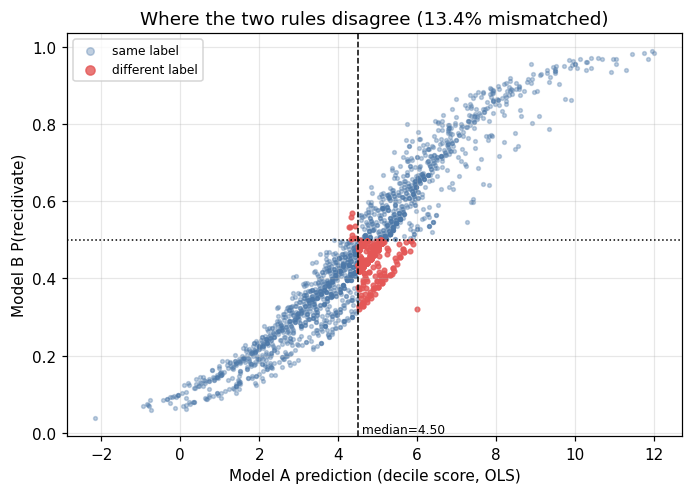

In [5]:
fig, ax = plt.subplots(figsize=(6.4, 4.6))
mm = flagA != flagB
ax.scatter(predA[~mm], pB[~mm], s=6, alpha=.35, c="#4c78a8", label="same label")
ax.scatter(predA[mm], pB[mm], s=9, alpha=.8, c="#e45756", label="different label")
ax.axvline(medA, color="k", ls="--", lw=1); ax.axhline(0.5, color="k", ls=":", lw=1)
ax.set_xlabel("Model A prediction (decile score, OLS)"); ax.set_ylabel("Model B P(recidivate)")
ax.set_title(f"Where the two rules disagree ({R['mism_pct']:.1f}% mismatched)")
ax.text(medA, ax.get_ylim()[0], f" median={medA:.2f}", va="bottom", fontsize=8)
ax.legend(markerscale=2, fontsize=8); plt.tight_layout()
fig.savefig(f"{OUT}/fig_part1.png", dpi=170); plt.show()

## 3. Part 2.1: Simpson's paradox hunt
I test four candidate splits (sex, charge degree, age group, race). For every split and every predictor I fit
logistic regression on (1) the **full dataset**, (2) **subgroup A**, (3) **subgroup B**, and compare coefficients with a
z-test on the difference: `z = (bA - bB) / sqrt(seA^2 + seB^2)`.
A "reversal" means the subgroup coefficient has the opposite sign to the full-data coefficient (and is significant at 5%).
If no reversal exists, the pair with the largest significant difference is documented instead.
Predictors are in standardised units (per 1 SD for numeric variables), so coefficients are comparable.

In [6]:
full_tab = logit_fit(X, y)                       # (1) full dataset

split_defs = {
    "sex":            ("Male", "Female",         (df["sex"] == "Male").values,              "sex_Male"),
    "charge degree":  ("Felony", "Misdemeanor",  (df["c_charge_degree"] == "F").values,     "charge_Felony"),
    "age group":      ("Age <= 30", "Age > 30",  (df["age"] <= 30).values,                  None),
    "race":           ("African-American", "Other races", (df["race_grp"] == "African-American").values, "race_African-American"),
}

def fit_sub(mask, drop):
    cols = [c for c in FEATURES if c != drop and X.loc[mask, c].std() > 0]
    return logit_fit(X.loc[mask, cols], y[mask])

cand_rows, sub_tabs = [], {}
for sname, (la, lb, mA, drop) in split_defs.items():
    mB = ~mA
    tA, tB = fit_sub(mA, drop), fit_sub(mB, drop)
    sub_tabs[sname] = (tA, tB)
    for pred in FEATURES:
        if pred == drop or pred not in tA.index or pred not in tB.index:
            continue
        bF, bA, bB = full_tab.loc[pred, "coef"], tA.loc[pred, "coef"], tB.loc[pred, "coef"]
        pA_, pB_, pF_ = tA.loc[pred, "p"], tB.loc[pred, "p"], full_tab.loc[pred, "p"]
        zdiff = (bA - bB) / math.sqrt(tA.loc[pred, "se"] ** 2 + tB.loc[pred, "se"] ** 2)
        reversal = bool((np.sign(bA) != np.sign(bF) and pA_ < .05) or (np.sign(bB) != np.sign(bF) and pB_ < .05))
        cand_rows.append(dict(split=sname, group_A=la, group_B=lb, predictor=pred, b_full=bF, b_A=bA, b_B=bB,
                              p_full=pF_, p_A=pA_, p_B=pB_, z_diff=zdiff, p_diff=2 * stats.norm.sf(abs(zdiff)),
                              reversal=reversal, n_A=int(mA.sum()), n_B=int(mB.sum())))
cand = pd.DataFrame(cand_rows)
cand["abs_z"] = cand["z_diff"].abs()
pool = cand[cand["reversal"]] if cand["reversal"].any() else cand[cand["p_diff"] < .05]
if pool.empty:
    pool = cand
best = pool.sort_values("abs_z", ascending=False).iloc[0]
sname, pred = best["split"], best["predictor"]
la, lb, mA, drop = split_defs[sname]
tA, tB = sub_tabs[sname]
simp = dict(split=sname, label_A=la, label_B=lb, predictor=pred, reversal=bool(best["reversal"]),
            n_A=int(best["n_A"]), n_B=int(best["n_B"]), z_diff=float(best["z_diff"]), p_diff=float(best["p_diff"]),
            rate_A=float(y[mA].mean()), rate_B=float(y[~mA].mean()), n_candidates=len(cand))
for tag, t in [("full", full_tab), ("A", tA), ("B", tB)]:
    simp.update({f"b_{tag}": float(t.loc[pred, "coef"]), f"lo_{tag}": float(t.loc[pred, "ci_low"]),
                 f"hi_{tag}": float(t.loc[pred, "ci_high"]), f"p_{tag}": float(t.loc[pred, "p"]),
                 f"or_{tag}": float(t.loc[pred, "odds_ratio"])})
R["simp"] = simp; R["simp_top"] = cand.sort_values("abs_z", ascending=False).head(8)
R["full_tab"] = full_tab
print("Reversal found:" , bool(cand["reversal"].any()), "| candidates tested:", len(cand))
print(f"Selected: split by {sname} ({la} vs {lb}), predictor = {pred}")
for tag in ["full", "A", "B"]:
    print(f"  {tag:>4}: coef = {simp['b_'+tag]:+.3f}  95% CI [{simp['lo_'+tag]:+.3f}, {simp['hi_'+tag]:+.3f}]  p = {simp['p_'+tag]:.4g}")
print(f"  difference test: z = {simp['z_diff']:.2f}, p = {simp['p_diff']:.4g}")
display_fn(R["simp_top"][["split", "predictor", "b_full", "b_A", "b_B", "z_diff", "p_diff", "reversal"]].round(3))

Reversal found: True | candidates tested: 35
Selected: split by sex (Male vs Female), predictor = race_African-American
  full: coef = +0.059  95% CI [-0.065, +0.184]  p = 0.3484
     A: coef = +0.150  95% CI [+0.012, +0.289]  p = 0.03321
     B: coef = -0.316  95% CI [-0.603, -0.030]  p = 0.0303
  difference test: z = 2.88, p = 0.004012
        split              predictor  b_full    b_A    b_B  z_diff  p_diff  \
18  age group                    age  -0.495 -1.474 -0.347  -6.352   0.000   
19  age group           priors_count   0.718  1.172  0.662   5.420   0.000   
32       race        juv_other_count   0.125  0.225  0.005   3.328   0.001   
6         sex  race_African-American   0.059  0.150 -0.316   2.877   0.004   
1         sex           priors_count   0.718  0.678  1.024  -2.826   0.005   
33       race               sex_Male   0.329  0.517  0.136   2.638   0.008   
25  age group  race_African-American   0.059  0.219 -0.105   2.525   0.012   
28       race                    age

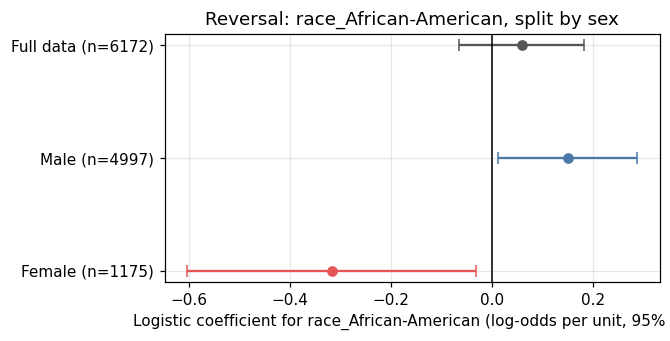

In [7]:
fig, ax = plt.subplots(figsize=(6.2, 3.2))
labels = [f"Full data (n={len(df)})", f"{la} (n={simp['n_A']})", f"{lb} (n={simp['n_B']})"]
vals = [(simp["b_" + k], simp["lo_" + k], simp["hi_" + k]) for k in ["full", "A", "B"]]
for i, (b, lo, hi) in enumerate(vals):
    ax.errorbar(b, i, xerr=[[b - lo], [hi - b]], fmt="o", capsize=4, color=["#555", "#4c78a8", "#e45756"][i])
ax.axvline(0, color="k", lw=1); ax.set_yticks(range(3)); ax.set_yticklabels(labels); ax.invert_yaxis()
ax.set_xlabel(f"Logistic coefficient for {pred} (log-odds per unit, 95% CI)")
ax.set_title(f"{'Reversal' if simp['reversal'] else 'Differing effect'}: {pred}, split by {sname}")
plt.tight_layout(); fig.savefig(f"{OUT}/fig_part21.png", dpi=170); plt.show()

## 4. Part 2.2: Omitted-variable bias
I deliberately drop **`priors_count`** (number of prior offences). It is the strongest predictor of recidivism and it is
correlated with age, race and sex (because of differential policing/arrest histories), so it is a textbook confounder.
I fit the full and reduced logistic models on the full dataset and compare coefficients.
I also add a *residual audit*: do the model's residuals correlate with information the model never saw?

In [8]:
red_features = [c for c in FEATURES if c != DROP_VAR]
tab_full2 = logit_fit(X, y)
tab_red = logit_fit(X[red_features], y)
ov = pd.DataFrame({"before (full)": tab_full2.loc[red_features, "coef"], "after (reduced)": tab_red.loc[red_features, "coef"]})
ov["abs change"] = ov["after (reduced)"] - ov["before (full)"]
ov["% change"] = 100 * ov["abs change"] / ov["before (full)"].abs()
ov["p before"] = tab_full2.loc[red_features, "p"]; ov["p after"] = tab_red.loc[red_features, "p"]
ov["corr with dropped var"] = X[red_features].corrwith(X[DROP_VAR])
elig = ov[ov["before (full)"].abs() >= 0.05]
elig = elig if len(elig) else ov
top_name = elig["% change"].abs().idxmax()
R["ov"] = ov; R["ov_top"] = top_name; R["ov_dropped_coef"] = float(tab_full2.loc[DROP_VAR, "coef"])
R["ov_dropped_z"] = float(tab_full2.loc[DROP_VAR, "z"])

# predictive consequences (train -> test)
t_full_tr = logit_fit(Xtr, ytr); t_red_tr = logit_fit(Xtr[red_features], ytr)
p_full_te = logit_predict(t_full_tr, Xte); p_red_te = logit_predict(t_red_tr, Xte)
R["ov_auc_full"] = float(roc_auc_score(yte, p_full_te)); R["ov_auc_red"] = float(roc_auc_score(yte, p_red_te))
R["ov_acc_full"] = float(np.mean((p_full_te >= .5) == yte)); R["ov_acc_red"] = float(np.mean((p_red_te >= .5) == yte))
# LR test for the dropped variable
lr = 2 * (tab_full2.attrs["ll"] - tab_red.attrs["ll"]); R["ov_lr"] = float(lr); R["ov_lr_p"] = float(stats.chi2.sf(lr, 1))
display_fn(ov.round(3))
print(f"\nLargest relative shift: {top_name} ({ov.loc[top_name, '% change']:+.1f}%)")
print(f"Test AUC full = {R['ov_auc_full']:.3f}, reduced = {R['ov_auc_red']:.3f}; accuracy full = {R['ov_acc_full']:.3f}, reduced = {R['ov_acc_red']:.3f}")

# ---- residual audit: information the model never saw ----
res = (yte - p_full_te) / np.sqrt(p_full_te * (1 - p_full_te))      # Pearson residuals on the test set
audit = {}
for name, v in [("COMPAS decile_score", dte), ("days_b_screening_arrest", df_te["days_b_screening_arrest"].values)]:
    r, p = stats.pearsonr(res, v); audit[name] = (float(r), float(p))
R["audit"] = audit
# does adding the COMPAS score (which uses extra survey items) improve a model fitted on train?
mu, sd = dtr.mean(), dtr.std()
Xtr_a, Xte_a = Xtr.copy(), Xte.copy(); Xtr_a["decile_std"] = (dtr - mu) / sd; Xte_a["decile_std"] = (dte - mu) / sd
t_aug = logit_fit(Xtr_a, ytr); p_aug = logit_predict(t_aug, Xte_a)
R["aug_auc"] = float(roc_auc_score(yte, p_aug)); R["aug_coef"] = float(t_aug.loc["decile_std", "coef"])
R["aug_p"] = float(t_aug.loc["decile_std", "p"])
print("Residual audit (Pearson r, p):", {k: (round(v[0], 3), round(v[1], 4)) for k, v in audit.items()})
print(f"Adding COMPAS decile as a predictor: coef = {R['aug_coef']:.3f} (p = {R['aug_p']:.3g}); test AUC {R['ov_auc_full']:.3f} -> {R['aug_auc']:.3f}")

                       before (full)  after (reduced)  abs change  % change  \
age                           -0.495           -0.300       0.195    39.446   
juv_fel_count                  0.006            0.124       0.117  1830.966   
juv_misd_count                 0.018            0.162       0.144   796.519   
juv_other_count                0.125            0.172       0.047    37.880   
sex_Male                       0.329            0.444       0.115    34.945   
charge_Felony                  0.220            0.379       0.159    72.115   
race_African-American          0.059            0.306       0.247   415.572   
race_Hispanic                 -0.175           -0.170       0.005     3.067   
race_Other                    -0.188           -0.235      -0.047   -25.298   

                       p before  p after  corr with dropped var  
age                       0.000    0.000                  0.117  
juv_fel_count             0.837    0.000                  0.229  
juv_misd_co

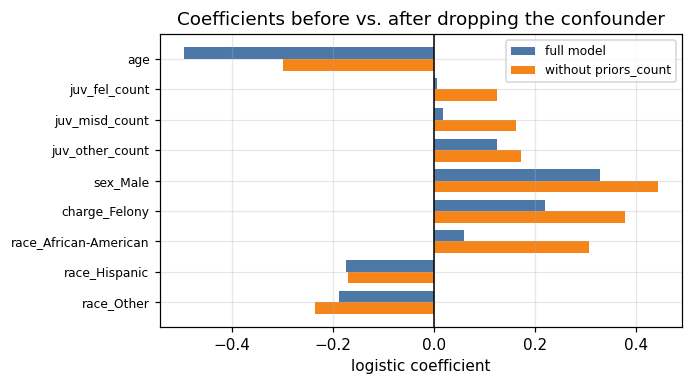

In [9]:
fig, ax = plt.subplots(figsize=(6.4, 3.6))
yy = np.arange(len(ov)); w = 0.38
ax.barh(yy - w / 2, ov["before (full)"], w, label="full model", color="#4c78a8")
ax.barh(yy + w / 2, ov["after (reduced)"], w, label=f"without {DROP_VAR}", color="#f58518")
ax.set_yticks(yy); ax.set_yticklabels(ov.index, fontsize=8); ax.axvline(0, color="k", lw=1); ax.invert_yaxis()
ax.set_xlabel("logistic coefficient"); ax.set_title("Coefficients before vs. after dropping the confounder"); ax.legend(fontsize=8)
plt.tight_layout(); fig.savefig(f"{OUT}/fig_part22.png", dpi=170); plt.show()

## 5. Part 2.3: Adversarial subset construction
Using Model B (trained on the training set) I find test rows where the model is **confidently wrong**:
`P >= 0.75` but actual outcome 0 (false positive) **or** `P <= 0.25` but actual outcome 1 (false negative).
If there are more than 50 such rows I draw a random sample of 50 (seeded); otherwise I keep them all.

{'total': 102, 'pct': 5.50755939524838, 'n_sample': 50, 'n_fp': 40, 'n_fn': 62, 'n_hi': 194, 'n_lo': 301, 'fp_rate_hi': 0.20618556701030927, 'fn_rate_lo': 0.2059800664451827, 'exp_fp_rate_hi': 0.14502428228625697, 'exp_fn_rate_lo': 0.17341319577138223, 'sample_fp': 22, 'sample_fn': 28}
                     statistic  adversarial rows  full test set
0                     Mean age             43.12          34.77
1                   Median age             44.00          31.00
2                       % male             80.00          81.70
3           % African-American             34.00          52.81
4                  % Caucasian             52.00          32.94
5            Mean priors_count              6.02           3.50
6          Median priors_count              3.00           1.00
7              % felony charge             48.00          64.31
8  Base rate of recidivism (%)             56.00          46.38
9             Mean predicted P              0.47           0.46
         

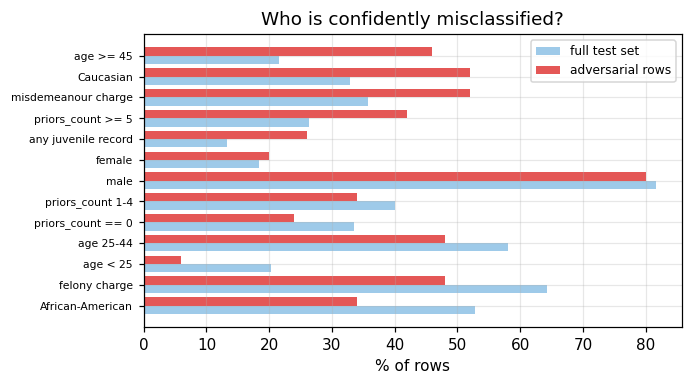

In [10]:
HI, LO = 0.75, 0.25
fp_mask = (pB >= HI) & (yte == 0)
fn_mask = (pB <= LO) & (yte == 1)
adv_mask = fp_mask | fn_mask
adv_idx_all = np.where(adv_mask)[0]
rng = np.random.default_rng(SEED)
adv_idx = np.sort(rng.choice(adv_idx_all, 50, replace=False)) if len(adv_idx_all) > 50 else adv_idx_all
n_hi, n_lo = int((pB >= HI).sum()), int((pB <= LO).sum())
R["adv"] = dict(total=len(adv_idx_all), pct=100 * len(adv_idx_all) / len(yte), n_sample=len(adv_idx),
                n_fp=int(fp_mask.sum()), n_fn=int(fn_mask.sum()), n_hi=n_hi, n_lo=n_lo,
                fp_rate_hi=float(fp_mask.sum() / n_hi) if n_hi else np.nan,
                fn_rate_lo=float(fn_mask.sum() / n_lo) if n_lo else np.nan,
                exp_fp_rate_hi=float(1 - pB[pB >= HI].mean()) if n_hi else np.nan,
                exp_fn_rate_lo=float(pB[pB <= LO].mean()) if n_lo else np.nan,
                sample_fp=int(fp_mask[adv_idx].sum()), sample_fn=int(fn_mask[adv_idx].sum()))
print(R["adv"])

sub = df_te.iloc[adv_idx]
traits = {
    "priors_count >= 5": lambda d: d["priors_count"] >= 5,
    "priors_count 1-4": lambda d: d["priors_count"].between(1, 4),
    "priors_count == 0": lambda d: d["priors_count"] == 0,
    "age < 25": lambda d: d["age"] < 25,
    "age 25-44": lambda d: d["age"].between(25, 44),
    "age >= 45": lambda d: d["age"] >= 45,
    "male": lambda d: d["sex"] == "Male",
    "female": lambda d: d["sex"] == "Female",
    "felony charge": lambda d: d["c_charge_degree"] == "F",
    "misdemeanour charge": lambda d: d["c_charge_degree"] == "M",
    "African-American": lambda d: d["race"] == "African-American",
    "Caucasian": lambda d: d["race"] == "Caucasian",
    "any juvenile record": lambda d: d["juv_total"] > 0,
}
trait_rows = []
for k, f in traits.items():
    s_sub, s_te = 100 * f(sub).mean() if len(sub) else np.nan, 100 * f(df_te).mean()
    trait_rows.append({"trait": k, "% of adversarial rows": s_sub, "% of test set": s_te, "difference (pp)": s_sub - s_te})
trait_tab = pd.DataFrame(trait_rows).sort_values("difference (pp)", ascending=False).reset_index(drop=True)
top_trait = trait_tab.iloc[0]
R["trait_tab"] = trait_tab; R["top_trait"] = top_trait.to_dict()

demo = pd.DataFrame({
    "statistic": ["Mean age", "Median age", "% male", "% African-American", "% Caucasian", "Mean priors_count", "Median priors_count",
                  "% felony charge", "Base rate of recidivism (%)", "Mean predicted P"],
    "adversarial rows": [sub["age"].mean(), sub["age"].median(), 100 * (sub["sex"] == "Male").mean(), 100 * (sub["race"] == "African-American").mean(),
                         100 * (sub["race"] == "Caucasian").mean(), sub["priors_count"].mean(), sub["priors_count"].median(),
                         100 * (sub["c_charge_degree"] == "F").mean(), 100 * yte[adv_idx].mean(), pB[adv_idx].mean()],
    "full test set": [df_te["age"].mean(), df_te["age"].median(), 100 * (df_te["sex"] == "Male").mean(), 100 * (df_te["race"] == "African-American").mean(),
                      100 * (df_te["race"] == "Caucasian").mean(), df_te["priors_count"].mean(), df_te["priors_count"].median(),
                      100 * (df_te["c_charge_degree"] == "F").mean(), 100 * yte.mean(), pB.mean()]})
R["adv_demo"] = demo
display_fn(demo.round(2)); display_fn(trait_tab.round(1))

# ---- why does it fail? 1) calibration in the confident bins; 2) is there neglected non-linearity / interaction? ----
Xtr2, Xte2 = Xtr.copy(), Xte.copy()
for D in (Xtr2, Xte2):
    D["priors_sq"] = D["priors_count"] ** 2
    D["age_x_priors"] = D["age"] * D["priors_count"]
    D["AA_x_priors"] = D["race_African-American"] * D["priors_count"]
t_ext = logit_fit(Xtr2, ytr); t_base = logit_fit(Xtr, ytr)
lr3 = 2 * (t_ext.attrs["ll"] - t_base.attrs["ll"])
p_ext = logit_predict(t_ext, Xte2)
R["nl"] = dict(lr=float(lr3), p=float(stats.chi2.sf(lr3, 3)), auc_base=R["auc_B"], auc_ext=float(roc_auc_score(yte, p_ext)),
               coef_sq=float(t_ext.loc["priors_sq", "coef"]), p_sq=float(t_ext.loc["priors_sq", "p"]),
               coef_int=float(t_ext.loc["age_x_priors", "coef"]), p_int=float(t_ext.loc["age_x_priors", "p"]),
               coef_aa=float(t_ext.loc["AA_x_priors", "coef"]), p_aa=float(t_ext.loc["AA_x_priors", "p"]),
               n_adv_changed=int(((p_ext >= HI) & (yte == 0) | (p_ext <= LO) & (yte == 1)).sum()))
R["coefB"] = tabB
print(R["nl"])

fig, ax = plt.subplots(figsize=(6.4, 3.6))
tt = trait_tab.sort_values("difference (pp)")
yy = np.arange(len(tt))
ax.barh(yy - .2, tt["% of test set"], .4, label="full test set", color="#9ecae9")
ax.barh(yy + .2, tt["% of adversarial rows"], .4, label="adversarial rows", color="#e45756")
ax.set_yticks(yy); ax.set_yticklabels(tt["trait"], fontsize=7); ax.set_xlabel("% of rows"); ax.legend(fontsize=8)
ax.set_title("Who is confidently misclassified?"); plt.tight_layout(); fig.savefig(f"{OUT}/fig_part23.png", dpi=170); plt.show()

## 6. Part 2.4: Fairness trade-off analysis
Sensitive variable: **race**. Group A = Caucasian, Group B = African-American (the two largest groups; only their test rows are used).
For each threshold t in {0.05, 0.15, ..., 0.95}: classify 1 if P >= t, then compute
* **DP** = P(Yhat=1 | A) / P(Yhat=1 | B)
* **EO** = min(TPR_A / TPR_B, FPR_A / FPR_B)
* **PP** = P(Y=1 | Yhat=1, A) / P(Y=1 | Yhat=1, B)

A is the group with the *lower* flag rate, so the ratios sit below or near 1 and fit the requested 0-1.5 axes.

      t     DP     EO     PP    acc  sel_A  sel_B  TPR_A  TPR_B  FPR_A  FPR_B
0  0.05  1.000  1.000  0.766  0.475  1.000  1.000  1.000  1.000  1.000  1.000
1  0.15  0.911  0.886  0.802  0.506  0.898  0.986  0.951  0.996  0.863  0.974
2  0.25  0.797  0.754  0.843  0.556  0.739  0.927  0.852  0.971  0.664  0.880
3  0.35  0.685  0.657  0.854  0.610  0.557  0.814  0.697  0.912  0.464  0.707
4  0.45  0.563  0.568  0.772  0.647  0.352  0.626  0.447  0.787  0.290  0.450
5  0.55  0.447  0.465  0.795  0.655  0.182  0.407  0.266  0.573  0.126  0.225
6  0.65  0.399  0.429  0.823  0.626  0.105  0.263  0.168  0.391  0.063  0.122
7  0.75  0.293  0.247  0.645  0.589  0.046  0.156  0.061  0.249  0.036  0.056
8  0.85  0.193  0.147  0.585  0.562  0.016  0.085  0.020  0.139  0.014  0.026
9  0.95  0.000  0.000    NaN  0.536  0.000  0.020  0.000  0.037  0.000  0.002
{'exists': True, 'gain': 'DP', 'loss': 'PP', 't_from': 0.65, 't_to': 0.45, 'gain_from': 0.3992600625119602, 'gain_to': 0.5632433301189328, 'lo

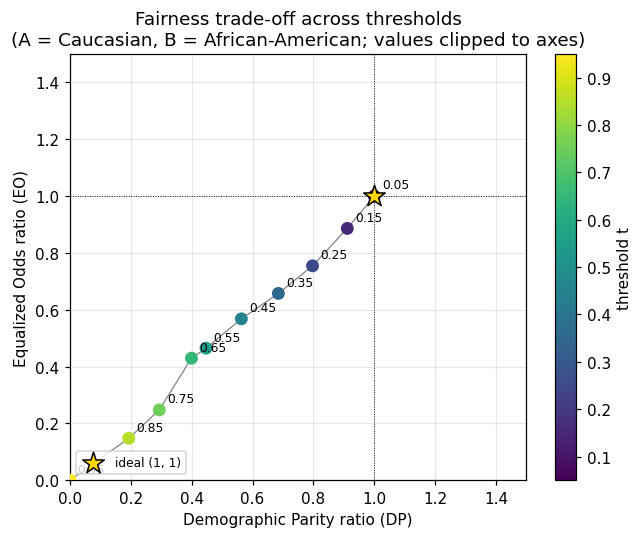

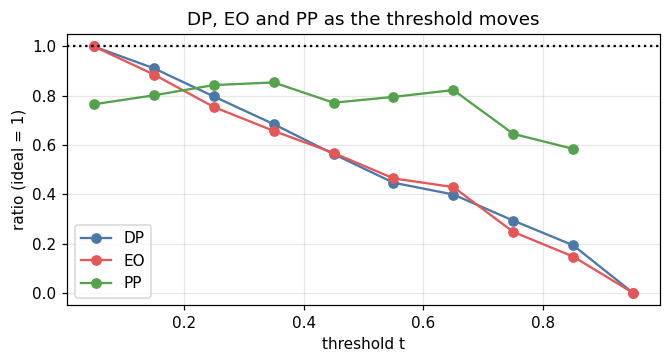

{'age': 24, 'priors': 1, 'sex': 'Male', 'charge': 'F', 'p': 0.6127052634465214} {'age': 24, 'priors': 1, 'sex': 'Male', 'charge': 'F', 'p': 0.5576282305701483} distance: 0.0


In [11]:
gA = (df_te["race"] == GROUP_A).values; gB = (df_te["race"] == GROUP_B).values
gm = gA | gB
yy_, pp_ = yte[gm], pB[gm]; isA = gA[gm]
rows = []
for t in THRESHOLDS:
    yh = (pp_ >= t).astype(int)
    def gstats(m):
        yg, hg = yy_[m], yh[m]
        return dict(sel=hg.mean(), tpr=hg[yg == 1].mean() if (yg == 1).any() else np.nan,
                    fpr=hg[yg == 0].mean() if (yg == 0).any() else np.nan,
                    ppv=yg[hg == 1].mean() if (hg == 1).any() else np.nan, n_flag=int(hg.sum()))
    a, b = gstats(isA), gstats(~isA)
    rows.append(dict(t=t, sel_A=a["sel"], sel_B=b["sel"], TPR_A=a["tpr"], TPR_B=b["tpr"], FPR_A=a["fpr"], FPR_B=b["fpr"],
                     PPV_A=a["ppv"], PPV_B=b["ppv"], nflag_A=a["n_flag"], nflag_B=b["n_flag"], DP=safe_div(a["sel"], b["sel"]),
                     EO=np.nanmin([safe_div(a["tpr"], b["tpr"]), safe_div(a["fpr"], b["fpr"])]) if not (np.isnan(safe_div(a["tpr"], b["tpr"])) and np.isnan(safe_div(a["fpr"], b["fpr"]))) else np.nan,
                     PP=safe_div(a["ppv"], b["ppv"]), acc=float(np.mean(yh == yy_)),
                     acc_A=float(np.mean(yh[isA] == yy_[isA])), acc_B=float(np.mean(yh[~isA] == yy_[~isA]))))
fair = pd.DataFrame(rows)
R["fair"] = fair; R["n_fair_A"] = int(isA.sum()); R["n_fair_B"] = int((~isA).sum())
display_fn(fair[["t", "DP", "EO", "PP", "acc", "sel_A", "sel_B", "TPR_A", "TPR_B", "FPR_A", "FPR_B"]].round(3))

# ---- trade-off quantification ----
# "informative" thresholds: neither group is flagged almost entirely / almost never (avoids trivial ratios of 1 or 0/0)
fair["informative"] = (fair[["sel_A", "sel_B"]].apply(lambda c: c.between(0.05, 0.95)).all(axis=1)
                       & (fair["nflag_A"] >= 20) & (fair["nflag_B"] >= 20))
valid = fair[fair["informative"]].dropna(subset=["DP", "EO", "PP"]).reset_index(drop=True)
if valid.empty:
    valid = fair.dropna(subset=["DP", "EO", "PP"]).reset_index(drop=True)
best_t = {m: float(valid.loc[(valid[m] - 1).abs().idxmin(), "t"]) for m in ["DP", "EO", "PP"]}

def find_tradeoff(gain_m, loss_m):
    """Best move (t_from -> t_to) that brings gain_m closer to 1 while pushing loss_m further from 1."""
    best_, score = None, 0.0
    for _, r1 in valid.iterrows():
        for _, r2 in valid.iterrows():
            g = abs(r1[gain_m] - 1) - abs(r2[gain_m] - 1); l = abs(r2[loss_m] - 1) - abs(r1[loss_m] - 1)
            if g > 0.01 and l > 0.01 and g * l > score:
                best_, score = (r1, r2), g * l
    return best_

tradeoff = dict(exists=False)
for gm_, lm_ in [("DP", "EO"), ("EO", "DP"), ("DP", "PP"), ("EO", "PP"), ("PP", "EO"), ("PP", "DP")]:
    found = find_tradeoff(gm_, lm_)
    if found:
        r1, r2 = found
        Z = 100 * abs(r2[gm_] - r1[gm_]) / abs(r1[gm_]); W = 100 * abs(r2[lm_] - r1[lm_]) / abs(r1[lm_])
        tradeoff = dict(exists=True, gain=gm_, loss=lm_, t_from=float(r1["t"]), t_to=float(r2["t"]),
                        gain_from=float(r1[gm_]), gain_to=float(r2[gm_]), loss_from=float(r1[lm_]), loss_to=float(r2[lm_]),
                        Z=float(Z), W=float(W), cost=float(W / Z) if Z > 0 else np.nan)
        break
tradeoff["best_t"] = best_t
tradeoff["dp_eo_conflict"] = bool(tradeoff.get("gain") == "DP" and tradeoff.get("loss") == "EO")
R["tradeoff"] = tradeoff; print(tradeoff)

# ---- automatic choice of a defensible threshold: near-best accuracy, smallest average distance from 1 ----
cands = valid[valid["acc"] >= valid["acc"].max() - 0.03]
cands = cands if len(cands) else valid
dev = (cands[["DP", "EO", "PP"]] - 1).abs().mean(axis=1)
t_auto = float(cands.loc[dev.idxmin(), "t"])
T_STAR = round(float(CHOSEN_T), 2) if CHOSEN_T is not None else t_auto
R["T_STAR"] = T_STAR; R["fair_star"] = fair[np.isclose(fair["t"], T_STAR)].iloc[0].to_dict()
R["fair_valid_ts"] = list(valid["t"])
print("Chosen threshold for Part 3 Q7:", T_STAR)

# ---- trade-off chart: x = DP, y = EO (0 - 1.5), labelled by threshold ----
fig, ax = plt.subplots(figsize=(6.0, 5.0))
ok = fair.dropna(subset=["DP", "EO"])
xs, ys = ok["DP"].clip(0, 1.5), ok["EO"].clip(0, 1.5)
sc = ax.scatter(xs, ys, c=ok["t"], cmap="viridis", s=55, zorder=3)
ax.plot(xs, ys, color="grey", lw=.8, zorder=2)
for xv, yv, t_ in zip(xs, ys, ok["t"]):
    ax.annotate(f"{t_:.2f}", (xv, yv), textcoords="offset points", xytext=(5, 5), fontsize=8)
ax.scatter([1], [1], marker="*", s=220, color="gold", edgecolor="k", zorder=4, label="ideal (1, 1)")
ax.axvline(1, color="k", lw=.6, ls=":"); ax.axhline(1, color="k", lw=.6, ls=":")
ax.set_xlim(0, 1.5); ax.set_ylim(0, 1.5)
ax.set_xlabel("Demographic Parity ratio (DP)"); ax.set_ylabel("Equalized Odds ratio (EO)")
ax.set_title(f"Fairness trade-off across thresholds\n(A = {GROUP_A}, B = {GROUP_B}; values clipped to axes)")
ax.legend(loc="lower left", fontsize=8); plt.colorbar(sc, label="threshold t"); plt.tight_layout()
fig.savefig(f"{OUT}/fig_part24.png", dpi=170); plt.show()

# ---- DP / EO / PP against the threshold (extra view) ----
fig, ax = plt.subplots(figsize=(6.2, 3.4))
for c, col in [("DP", "#4c78a8"), ("EO", "#e45756"), ("PP", "#54a24b")]:
    ax.plot(fair["t"], fair[c].clip(0, 2), "o-", label=c, color=col)
ax.axhline(1, color="k", ls=":"); ax.set_xlabel("threshold t"); ax.set_ylabel("ratio (ideal = 1)"); ax.legend()
ax.set_title("DP, EO and PP as the threshold moves"); plt.tight_layout(); fig.savefig(f"{OUT}/fig_part24b.png", dpi=170); plt.show()

# ---- two real people from the test set for the Part 3 Q6 scenario ----
ia, ib = np.where(isA & (yy_ == 0))[0], np.where((~isA) & (yy_ == 0))[0]       # non-recidivists in each group
te_gm = df_te.loc[gm].reset_index(drop=True)
Aa, Bb = te_gm.iloc[ia], te_gm.iloc[ib]
dist = (np.abs(Aa["age"].to_numpy(float)[:, None] - Bb["age"].to_numpy(float)[None, :]) / 5 + np.abs(Aa["priors_count"].to_numpy(float)[:, None] - Bb["priors_count"].to_numpy(float)[None, :])
        + np.abs(Aa["juv_total"].to_numpy(float)[:, None] - Bb["juv_total"].to_numpy(float)[None, :]))
_sx_a, _sx_b = Aa["sex"].to_numpy(dtype=object), Bb["sex"].to_numpy(dtype=object)
_ch_a, _ch_b = Aa["c_charge_degree"].to_numpy(dtype=object), Bb["c_charge_degree"].to_numpy(dtype=object)
dist = dist + 100 * ((_sx_a[:, None] != _sx_b[None, :]) | (_ch_a[:, None] != _ch_b[None, :]))
gap = np.abs(pp_[ia][:, None] - pp_[ib][None, :])
order = np.lexsort((-gap.ravel(), dist.ravel())); k = order[0]
ra, rb = divmod(k, dist.shape[1])
pa, pb_ = Aa.iloc[ra], Bb.iloc[rb]
pair = dict(A=dict(age=int(pa["age"]), priors=int(pa["priors_count"]), sex=pa["sex"], charge=pa["c_charge_degree"], p=float(pp_[ia][ra])),
            B=dict(age=int(pb_["age"]), priors=int(pb_["priors_count"]), sex=pb_["sex"], charge=pb_["c_charge_degree"], p=float(pp_[ib][rb])),
            dist=float(dist[ra, rb]))
pair["decisions"] = [dict(t=float(t), flag_A=int(pair["A"]["p"] >= t), flag_B=int(pair["B"]["p"] >= t)) for t in THRESHOLDS]
R["pair"] = pair; print(pair["A"], pair["B"], "distance:", pair["dist"])

## 7. Parts 3 and 4: written answers (numbers filled in from `R`)
The answers below are **assembled from the results computed above**, so every figure quoted matches the code.
Wording adapts to what the data showed (e.g. reversal vs. no reversal). Word counts are printed so you can check the
250-300 word target for Part 3 and about 500 words for Part 4. **Read each answer and edit the wording in your own style**
(change the template strings in this cell, then re-run) before you submit.

In [12]:
def pc(x, d=1):  return f"{100 * x:.{d}f}%"
def pv(p):       return "< 0.001" if p < 0.001 else f"{p:.3f}"
def nwords(t):   return len(re.findall(r"\b[\w'\-\.%]+\b", t))

S, ADV, NL, TO, FS, OV = R["simp"], R["adv"], R["nl"], R["tradeoff"], R["fair_star"], R["ov"]
FAIR = R["fair"]; TB = R["coefB"]; T_STAR = R["T_STAR"]
base_A, base_B = float(yy_[isA].mean()), float(yy_[~isA].mean())
R["base_A"], R["base_B"] = base_A, base_B
la, lb = S["label_A"], S["label_B"]

def row_at(t):
    return FAIR[np.isclose(FAIR["t"], t)].iloc[0]

# ---------- Q1 ----------
def q1():
    stricter = (f"Because 0.5 is a stricter bar than the median here ({R['flagged_B']:.1f}% flagged versus {R['flagged_A']:.1f}%), "
                f"almost every mismatch is someone the linear rule flags but the logistic rule does not.") if R["flagged_B"] < R["flagged_A"] else \
               (f"Because 0.5 is a looser bar than the median here ({R['flagged_B']:.1f}% flagged versus {R['flagged_A']:.1f}%), "
                f"almost every mismatch is someone the logistic rule flags but the linear rule does not.")
    return (f"Of the {R['n_test']} individuals in the test set, the two rules label {R['mism_n']} ({R['mism_pct']:.1f}%) differently, "
            f"so they agree on {R['agree_pct']:.1f}%. The split is lopsided: {R['A_only']} people are high risk only under the thresholded linear model, "
            f"while {R['B_only']} are high risk only under logistic regression. The main reason is where each cut-off sits. "
            f"The median of the linear model's test predictions is {R['median_A']:.2f} on the 1-10 decile scale, so by construction the median rule labels "
            f"{R['flagged_A']:.1f}% of people high risk, however risky the population really is. The logistic rule asks whether P(recidivism) is at least 0.5, "
            f"and it labels {R['flagged_B']:.1f}% high risk, while the observed two-year recidivism rate in the test set is {pc(R['base_rate_test'])}. {stricter} "
            f"The median of the logistic probabilities is {R['median_pB']:.3f}, so a median rule applied to Model B would use that cut-off instead of 0.5. "
            f"The models also optimise different targets. OLS minimises squared error on COMPAS's own decile score (test R-squared = {R['r2_A']:.3f}, mean absolute error "
            f"{R['mae_A']:.2f} deciles), so its output describes the scoring tool rather than a probability of reoffending. Logistic regression is fitted to the actual outcome "
            f"and reaches accuracy {R['acc_B']:.3f} and AUC {R['auc_B']:.3f}, whereas the median-thresholded OLS label matches the true outcome {R['acc_Alabel']:.3f} of the time. "
            f"The two rankings are nevertheless similar (Spearman correlation {R['spearman']:.3f}), so the models mostly agree on who is riskier. "
            f"The {R['mism_pct']:.1f}% mismatch is therefore mainly a cut-off effect, a relative median rule against an absolute probability of 0.5, "
            f"compounded by different targets, and not evidence that the models rank people in contradictory ways.")

# ---------- Q2 ----------
def q2():
    if S["reversal"]:
        grp = la if (np.sign(S["b_A"]) != np.sign(S["b_full"]) and S["p_A"] < .05) else lb
        bg = S["b_A"] if grp == la else S["b_B"]
        branch = (f"The sign reverses: the pooled model says a higher {S['predictor']} {'raises' if S['b_full'] > 0 else 'lowers'} the odds of recidivism, "
                  f"but within {grp} it {'raises' if bg > 0 else 'lowers'} them. This is the Simpson's-paradox pattern, because the pooled coefficient is a "
                  f"weighted blend of different within-group relationships.")
    else:
        hi_g, lo_g = (la, lb) if abs(S["b_A"]) > abs(S["b_B"]) else (lb, la)
        overlap = not (S["hi_A"] < S["lo_B"] or S["hi_B"] < S["lo_A"])
        branch = (f"The sign does not reverse, so this is not a strict Simpson's paradox, but the effect is clearly stronger for {hi_g} than for {lo_g}, "
                  f"and the two confidence intervals {'still overlap' if overlap else 'do not overlap'}. The pooled coefficient is a compromise that "
                  f"describes neither group.")
    under, over = (la, lb) if abs(S["b_A"]) > abs(S["b_B"]) else (lb, la)
    sig = "statistically significant" if S["p_diff"] < .05 else "not statistically significant"
    return (f"I split the data by {S['split']}: {la} (n = {S['n_A']}) versus {lb} (n = {S['n_B']}), and tracked the effect of {S['predictor']} in standardised units. "
            f"In the full model its coefficient is {S['b_full']:+.3f} (95% CI [{S['lo_full']:+.3f}, {S['hi_full']:+.3f}], odds ratio {S['or_full']:.2f}). "
            f"In subgroup A ({la}) it is {S['b_A']:+.3f} (95% CI [{S['lo_A']:+.3f}, {S['hi_A']:+.3f}], odds ratio {S['or_A']:.2f}), and in subgroup B ({lb}) it is "
            f"{S['b_B']:+.3f} (95% CI [{S['lo_B']:+.3f}, {S['hi_B']:+.3f}], odds ratio {S['or_B']:.2f}). {branch} The gap between the subgroup coefficients is {sig} "
            f"(z = {S['z_diff']:.2f}, p = {pv(S['p_diff'])}). The groups also differ in baseline risk: {pc(S['rate_A'])} of {la} recidivate versus {pc(S['rate_B'])} of {lb}, "
            f"so a single pooled slope mixes populations with different intercepts and different slopes, and its value of {S['b_full']:+.3f} sits between {S['b_A']:+.3f} and {S['b_B']:+.3f} "
            f"without matching either. If the subgroup were ignored, a policy built on the pooled model would assume that one standard deviation of {S['predictor']} multiplies the odds by "
            f"{S['or_full']:.2f} for everyone, when the true multipliers are {S['or_A']:.2f} for {la} and {S['or_B']:.2f} for {lb}. The pooled model would then understate the effect for {under} "
            f"and overstate it for {over}, so any release, supervision or intervention rule keyed on {S['predictor']} would be miscalibrated for one group, "
            f"and the conclusion that {S['predictor']} matters equally across {S['split']} groups would be wrong. That is why the subgroup view must come before any policy is written.")

# ---------- Q3 ----------
def q3():
    o = OV.reindex(OV["% change"].abs().sort_values(ascending=False).index)
    four = "; ".join(f"{n} ({r['before (full)']:+.3f} to {r['after (reduced)']:+.3f}, {r['% change']:+.1f}%)" for n, r in o.head(4).iterrows())
    top = R["ov_top"]; r = OV.loc[top]
    top_abs = OV["abs change"].abs().idxmax()
    c_aa = OV.loc["race_African-American", "corr with dropped var"] if "race_African-American" in OV.index else float("nan")
    c_age = OV.loc["age", "corr with dropped var"] if "age" in OV.index else float("nan")
    return (f"I dropped {DROP_VAR}, the number of prior offences, because it is the strongest predictor in the full model (coefficient {R['ov_dropped_coef']:+.3f}, z = {R['ov_dropped_z']:.1f}) "
            f"and a likely confounder of age, race and sex. A likelihood-ratio test shows it matters (LR = {R['ov_lr']:.1f}, p = {pv(R['ov_lr_p'])}). Removing it changes test AUC from "
            f"{R['ov_auc_full']:.3f} to {R['ov_auc_red']:.3f} and accuracy from {R['ov_acc_full']:.3f} to {R['ov_acc_red']:.3f}. Table 2.2 lists all {len(OV)} remaining predictors; "
            f"the four largest relative shifts are {four}. The coefficient that shifted most (among those with a meaningful starting size) is {top}, from {r['before (full)']:+.3f} to "
            f"{r['after (reduced)']:+.3f}, a change of {r['% change']:+.1f}%; the largest absolute move is {top_abs} ({OV.loc[top_abs, 'abs change']:+.3f}). "
            f"Percentage changes look dramatic when the starting coefficient is close to zero, so I read them together with the absolute changes. "
            f"The mechanism is the omitted-variable formula: the dropped variable is correlated with the remaining ones (its correlation with age is {c_age:.2f} and with "
            f"race_African-American is {c_aa:.2f}), so they absorb part of its effect. The lesson is that a model can fit reasonably well, with an AUC of {R['ov_auc_full']:.3f}, "
            f"and still hand out misleading coefficients, and I could not have seen the {r['% change']:+.1f}% shift from the fit statistics alone. I would not trust any coefficient-based "
            f"or fairness conclusion from a model that has not been stress-tested by adding and removing plausible confounders in this way. "
            f"In practice this means reporting the full and reduced coefficients side by side, flagging every predictor whose estimate moves by more than about ten percent, "
            f"and treating those predictors as unreliable until a domain expert explains why the variable they are entangled with belongs in the model.")

# ---------- Q4 ----------
def q4():
    a = R["audit"]; dec_r, dec_p = a["COMPAS decile_score"]; day_r, day_p = a["days_b_screening_arrest"]
    verdict = ("so the residuals still carry some signal the model did not capture, which is a warning sign of omitted information"
               if (dec_p < .05 or R["aug_p"] < .05) else
               "so I find no strong sign of omitted signal in the extra information I could access, although that is weak reassurance")
    return (f"I would run a domain-expert audit combined with a residual and external-validation check. First, I would ask probation officers, defence lawyers and criminologists "
            f"to list variables that plausibly drive both the recorded features and the outcome, for example neighbourhood policing intensity, employment, housing stability and "
            f"substance-use treatment. Second, I would obtain those variables for a validation sample from a different county or a later year, and test whether the model's Pearson "
            f"residuals correlate with them and whether adding them shifts the key coefficients, exactly as in my {DROP_VAR} experiment. In my own data I could run only a weak version "
            f"using columns I had left out. The residuals correlate at r = {dec_r:.3f} (p = {pv(dec_p)}) with the COMPAS decile score and r = {day_r:.3f} (p = {pv(day_p)}) with the "
            f"days between arrest and screening. Adding the COMPAS decile to the model gives a coefficient of {R['aug_coef']:+.3f} (p = {pv(R['aug_p'])}) and moves test AUC from "
            f"{R['ov_auc_full']:.3f} to {R['aug_auc']:.3f}, {verdict}. Part 2.2 also gives a yardstick: removing {DROP_VAR} moved a coefficient by {OV.loc[R['ov_top'], '% change']:+.1f}%, "
            f"so I would treat any candidate variable whose inclusion moves a key coefficient by more than about 10 to 20 percent as a material confounder. The limitation is that "
            f"a confound nobody measured, such as true offending behaviour as opposed to arrests, cannot be detected from residuals at all. That is why the final check is "
            f"external validation: if coefficients and calibration are unstable across sites, a hidden variable is likely, and I would pause deployment until experts explain the difference.")

# ---------- Q5 ----------
def q5():
    tt = R["top_trait"]; d = R["adv_demo"].set_index("statistic")
    dom_fn = ADV["sample_fn"] >= ADV["sample_fp"]
    kind = "false negatives (rated low risk, but they reoffended)" if dom_fn else "false positives (rated high risk, but they did not reoffend)"
    mech = (f"These people look low risk on the recorded features, so the additive log-odds score pushes P below 0.25, yet recidivism among them depends on information the model does not record."
            if dom_fn else
            f"These people look high risk on the recorded features, so the additive log-odds score pushes P above 0.75, yet many of them did not reoffend for reasons the model does not record.")
    nl_txt = (f"Adding priors squared, age-by-priors and race-by-priors terms improves the fit significantly (LR = {NL['lr']:.1f}, 3 df, p = {pv(NL['p'])}), "
              f"which means the strictly additive form is part of the problem, although test AUC only moves from {NL['auc_base']:.3f} to {NL['auc_ext']:.3f}."
              if NL["p"] < .05 else
              f"Adding priors squared, age-by-priors and race-by-priors terms does not improve the fit significantly (LR = {NL['lr']:.1f}, 3 df, p = {pv(NL['p'])}; AUC "
              f"{NL['auc_base']:.3f} to {NL['auc_ext']:.3f}), so the failure is mostly unmodelled individual variation rather than a missing interaction.")
    return (f"My adversarial set contains {ADV['total']} confident errors, {ADV['pct']:.1f}% of the {R['n_test']} test rows: {ADV['n_fp']} false positives with P >= 0.75 and "
            f"{ADV['n_fn']} false negatives with P <= 0.25 (I analysed {ADV['n_sample']} rows). The sample is dominated by {kind}. The trait that most separates these rows from the "
            f"test set is '{tt['trait']}', present in {tt['% of adversarial rows']:.1f}% of them against {tt['% of test set']:.1f}% of the test set. Their mean age is "
            f"{d.loc['Mean age','adversarial rows']:.1f} (test set {d.loc['Mean age','full test set']:.1f}), and the actual recidivism rate among them is "
            f"{d.loc['Base rate of recidivism (%)','adversarial rows']:.1f}% against a mean predicted probability of {d.loc['Mean predicted P','adversarial rows']:.2f}. "
            f"Statistically there are two causes. First, calibration: of the {ADV['n_hi']} test rows with P >= 0.75, {pc(ADV['fp_rate_hi'])} did not reoffend, against "
            f"{pc(ADV['exp_fp_rate_hi'])} expected from the model's own probabilities; of the {ADV['n_lo']} rows with P <= 0.25, {pc(ADV['fn_rate_lo'])} did reoffend, against "
            f"{pc(ADV['exp_fn_rate_lo'])} expected. A probability of 0.8 is wrong one time in five by design, so some confident failure is irreducible. Second, structure: the model is "
            f"additive on the log-odds scale, with coefficients of {TB.loc['priors_count','coef']:+.3f} for priors_count and {TB.loc['age','coef']:+.3f} for age per standard deviation, "
            f"so a few strong features dominate the score. {mech} {nl_txt} "
            f"The practical reading is that these individuals sit in regions where the model is most sure and the data are least informative, so extra confidence is not earned.")

# ---------- Q6 ----------
EXPL = {"DP": "the two groups are flagged at different rates, so one group carries more of the burden of being labelled high risk",
        "EO": "people who would not have reoffended are wrongly flagged more often in one group than in the other",
        "PP": "a high-risk label means something different in each group, because a different share of the flagged people actually reoffend"}
def q6():
    p = R["pair"]; A_, B_ = p["A"], p["B"]
    diff_ts = [d["t"] for d in p["decisions"] if d["flag_A"] != d["flag_B"]]
    who = (f"B is flagged and A is not at t = {', '.join(f'{t:.2f}' for t in diff_ts)}" if diff_ts and B_["p"] > A_["p"] else
           f"A is flagged and B is not at t = {', '.join(f'{t:.2f}' for t in diff_ts)}" if diff_ts else
           "the two receive the same decision at every threshold in the sweep")
    fr = row_at(T_STAR)
    if TO["exists"]:
        tr = (f"Prioritising {TO['gain']} by moving from t = {TO['t_from']:.2f} to t = {TO['t_to']:.2f} lifts {TO['gain']} from {TO['gain_from']:.2f} to {TO['gain_to']:.2f} "
              f"(a {TO['Z']:.0f}% change), but moves {TO['loss']} from {TO['loss_from']:.2f} to {TO['loss_to']:.2f} (a {TO['W']:.0f}% change, trade-off cost {TO['cost']:.2f}). "
              f"In human terms, {EXPL[TO['loss']]}.")
    else:
        tr = "In my sweep no pair of thresholds improved one metric at the expense of another, so the cost shows up only as fewer people flagged overall."
    return (f"Take two real test-set individuals who did not reoffend within two years. Person A is a {A_['age']}-year-old {GROUP_A} {A_['sex'].lower()} with {A_['priors']} prior offences "
            f"and a {'felony' if A_['charge']=='F' else 'misdemeanour'} charge; person B is a {B_['age']}-year-old {GROUP_B} {B_['sex'].lower()} with {B_['priors']} prior offences and the same charge "
            f"degree. Their records are nearly identical, yet the model assigns A a risk of {A_['p']:.2f} and B a risk of {B_['p']:.2f}. Across my sweep, {who}. Neither person "
            f"reoffended, so any flag on either is a false positive: a harsher bail condition, a longer supervision order or a denied release for someone who did nothing. "
            f"At my chosen threshold t = {T_STAR:.2f}, {pc(FS['FPR_B'])} of {GROUP_B} non-recidivists are wrongly flagged versus {pc(FS['FPR_A'])} of {GROUP_A} non-recidivists, "
            f"while {pc(FS['TPR_B'])} of {GROUP_B} recidivists are caught versus {pc(FS['TPR_A'])} of {GROUP_A}. {tr} Raising the threshold protects people like A and B from false flags, "
            f"but it also lets more genuine reoffenders go unflagged. The group whose people are mislabelled more often pays the cost of whichever fairness metric is not prioritised, "
            f"and the chart shows that no threshold removes that cost for both groups at once. For a real person this is the difference between walking out on standard conditions "
            f"and spending months under extra supervision, simply because the cut-off was set at one value rather than another, and the person making that choice may never see the trade-off.")

# ---------- Q7 ----------
def q7():
    fr = row_at(T_STAR)
    devs = {m: abs(fr[m] - 1) for m in ["DP", "EO", "PP"]}
    worst = max(devs, key=devs.get); bt = TO["best_t"][worst]; rb = row_at(bt)
    crit = {"DP": f"the flag rates are still unequal ({pc(fr['sel_A'])} for {GROUP_A} versus {pc(fr['sel_B'])} for {GROUP_B})",
            "EO": f"the false-positive rates still differ ({pc(fr['FPR_A'])} versus {pc(fr['FPR_B'])}), so non-recidivists in {GROUP_B} are flagged more often",
            "PP": f"a high-risk label is right {pc(fr['PPV_A'])} of the time for {GROUP_A} but {pc(fr['PPV_B'])} for {GROUP_B}"}[worst]
    return (f"I choose t = {T_STAR:.2f}. Its metrics are DP = {fr['DP']:.2f}, EO = {fr['EO']:.2f} and PP = {fr['PP']:.2f}, with overall accuracy {fr['acc']:.3f} on the two-group test sample "
            f"({GROUP_A} accuracy {fr['acc_A']:.3f}, {GROUP_B} {fr['acc_B']:.3f}). It is defensible for three reasons. First, accuracy stays within three points of the best value in the sweep "
            f"({FAIR['acc'].max():.3f}), so I am not buying fairness by throwing away predictive power. Second, among the thresholds that flag a meaningful share of both groups, it has the "
            f"smallest average distance from 1 across the three metrics ({np.mean([devs[m] for m in devs]):.2f}). Third, the group flag rates are {pc(fr['sel_A'])} and {pc(fr['sel_B'])}, so neither "
            f"group is flagged almost wholesale or almost never, which avoids the degenerate ratios that appear at the extremes of the sweep. The strongest counter-argument is about {worst}: "
            f"{crit}. A critic could argue that a threshold which leaves {worst} at {fr[worst]:.2f} still treats the groups unequally, and that t = {bt:.2f}, where {worst} = {rb[worst]:.2f}, "
            f"would be fairer on that measure. That objection is valid. The cost of switching is that other metrics move (at t = {bt:.2f}, accuracy is {rb['acc']:.3f}, DP = {rb['DP']:.2f}, "
            f"EO = {rb['EO']:.2f}, PP = {rb['PP']:.2f}), and choosing between them is a values judgement. I defend t = {T_STAR:.2f} as a balanced compromise, not as a neutral answer. "
            f"A second objection is that the accuracy of {fr['acc']:.3f} is modest, so any threshold will mislabel many people; I accept this, and it is the reason I would present the "
            f"threshold to decision-makers together with the sweep table rather than as a fixed rule. If the court or agency values avoiding wrongful flags above everything else, "
            f"a higher threshold is the better choice, and my analysis would support that decision just as well, because the table lets them see exactly what each choice costs.")

# ---------- Q8 ----------
def q8():
    fr = row_at(T_STAR)
    if TO["exists"]:
        ts = (f"In my sweep, moving from t = {TO['t_from']:.2f} to t = {TO['t_to']:.2f} changes {TO['gain']} from {TO['gain_from']:.2f} to {TO['gain_to']:.2f} (a {TO['Z']:.0f}% change) while "
              f"{TO['loss']} changes from {TO['loss_from']:.2f} to {TO['loss_to']:.2f} (a {TO['W']:.0f}% change), a trade-off cost of {TO['cost']:.2f}.")
    else:
        ts = "In my sweep no pair of thresholds showed a clean trade-off between the metrics."
    bt = TO["best_t"]
    return (f"I would recommend prioritising equalized odds. In a recidivism setting the harm comes from errors: a false positive means someone who would not have reoffended is detained or "
            f"supervised more heavily, and a false negative means a real risk is missed. Equalized odds compares exactly those error rates across groups. At my chosen threshold t = {T_STAR:.2f}, "
            f"EO = {fr['EO']:.2f}, with false-positive rates of {pc(fr['FPR_A'])} for {GROUP_A} and {pc(fr['FPR_B'])} for {GROUP_B}, and true-positive rates of {pc(fr['TPR_A'])} and {pc(fr['TPR_B'])}. "
            f"Demographic parity would require equal flag rates even though the observed recidivism rates differ ({pc(base_A)} for {GROUP_A} against {pc(base_B)} for {GROUP_B} in the test sample), "
            f"so enforcing it would mean flagging people at rates unrelated to their outcomes, and the actual DP at t = {T_STAR:.2f} is {fr['DP']:.2f}. {ts} The best thresholds for each metric differ "
            f"(DP at t = {bt['DP']:.2f}, EO at t = {bt['EO']:.2f}, PP at t = {bt['PP']:.2f}), so no single threshold satisfies all three. By prioritising EO I accept that the two groups will be "
            f"flagged at unequal rates (DP = {fr['DP']:.2f}) and that predictive parity may drift (PP = {fr['PP']:.2f}). I find that acceptable because the burden of wrongful flags falls on identifiable "
            f"people, and the gap in flag rates can be monitored and explained by base-rate differences, but only if those base rates are not themselves the product of unequal policing, "
            f"which this dataset cannot tell me.")

# ---------- Part 4 ----------
def p4():
    fr = row_at(T_STAR); bt = TO["best_t"]
    direct = (f"I would recommend conditional deployment only: the model may serve as one advisory input reviewed by a human, never as an automated gate, because its test accuracy of "
              f"{R['acc_B']:.3f} (AUC {R['auc_B']:.3f}) hides unequal error rates between {GROUP_A} and {GROUP_B}.")
    why = (f"A single deploy-or-not number hides at least five things that I found myself. First, overall accuracy averages over groups and so conceals subgroup gaps: the same model "
           f"performs differently for each group, and the fairness sweep shows that error rates, not just accuracy, differ between them. Second, the threshold is a values question, not a data-driven fact. "
           f"Moving t from 0.05 to 0.95 changes who is flagged from nearly everyone to almost no one, and nothing in the data says how many wrongful flags are worth one extra caught reoffender; "
           f"that trade-off belongs to the policymaker and the affected community. Third, fairness metrics conflict. Demographic parity, equalized odds and predictive parity are each best at "
           f"different thresholds, so declaring the model 'fair' depends on which definition is chosen, and a single score would silently choose one. Fourth, the model fails confidently on "
           f"predictable subsets. Its high-confidence mistakes cluster around identifiable traits, so an average error rate understates the risk to specific people, and a probability of 0.8 is still "
           f"wrong one time in five. Fifth, hidden confounds remain unknowable. Removing one variable I could observe reshaped other coefficients, and the variables I cannot observe could do the same "
           f"without leaving any trace in the fit statistics. A single number would therefore present one point on a surface of trade-offs as if it were a property of the model, hiding the "
           f"assumptions, the affected groups and the uncertainty that a decision-maker needs to see. It also invites the wrong kind of accountability. If the number is good, nobody asks who "
           f"bears the errors; if it is bad, nobody learns which part of the pipeline failed. Reporting a table of subgroup error rates, a threshold sweep and a list of known blind spots "
           f"makes the same model auditable, and lets the people who live with its mistakes argue about whether the trade-offs are acceptable instead of having them settled out of sight.")
    ev = (f"Evidence: overall test accuracy is {R['acc_B']:.3f} but at t = {T_STAR:.2f} the false-positive rates are {pc(fr['FPR_A'])} ({GROUP_A}) versus {pc(fr['FPR_B'])} ({GROUP_B}). "
          f"DP, EO and PP are best at t = {bt['DP']:.2f}, {bt['EO']:.2f} and {bt['PP']:.2f}. There are {ADV['total']} confident errors ({ADV['pct']:.1f}% of the test set). "
          f"Dropping {DROP_VAR} shifted {R['ov_top']} by {OV.loc[R['ov_top'], '% change']:+.1f}%, and the {S['predictor']} effect differs across {S['split']} groups ({S['b_A']:+.3f} versus {S['b_B']:+.3f}). "
          f"Simply changing the cut-off rule flipped the label of {R['mism_pct']:.1f}% of individuals, so the threshold alone changes who is flagged.")
    close = ("The meta-lesson is that responsible deployment depends on being open about trade-offs, uncertainties and the people they affect. "
             "A model should travel with its threshold rationale, subgroup results and known blind spots, because a single metric invites false confidence, and trade-offs that stay hidden cannot be challenged or corrected.")
    return direct, why, ev, close

ANSWERS = {f"Q{i}": f() for i, f in enumerate([q1, q2, q3, q4, q5, q6, q7, q8], 1)}
P4 = p4(); R["answers"] = ANSWERS; R["p4"] = P4
wc = {k: nwords(v) for k, v in ANSWERS.items()}
wc["Part 4 (total)"] = sum(nwords(x) for x in P4)
wc["  P4 direct answer"] = nwords(P4[0]); wc["  P4 why a single number fails"] = nwords(P4[1])
wc["  P4 evidence"] = nwords(P4[2]); wc["  P4 closing"] = nwords(P4[3])
print("Word counts (targets: Part 3 about 250-300 each; Part 4 about 500; why-fails 300-400; evidence 50-100; closing about 50):")
for k, v in wc.items():
    flag = ""
    if k.startswith("Q") and not 250 <= v <= 300: flag = "  <-- outside 250-300, edit the template"
    print(f"  {k:32s} {v}{flag}")
R["wordcounts"] = wc
for k, v in ANSWERS.items(): print(f"\n[{k}] {v}")
print("\n[Part 4]"); [print(x, "\n") for x in P4]

Word counts (targets: Part 3 about 250-300 each; Part 4 about 500; why-fails 300-400; evidence 50-100; closing about 50):
  Q1                               282
  Q2                               254
  Q3                               280
  Q4                               267
  Q5                               276
  Q6                               287
  Q7                               295
  Q8                               256
  Part 4 (total)                   486
    P4 direct answer               39
    P4 why a single number fails   320
    P4 evidence                    78
    P4 closing                     49

[Q1] Of the 1852 individuals in the test set, the two rules label 248 (13.4%) differently, so they agree on 86.6%. The split is lopsided: 239 people are high risk only under the thresholded linear model, while 9 are high risk only under logistic regression. The main reason is where each cut-off sits. The median of the linear model's test predictions is 4.50 on the 1-10 d

[None, None, None, None]

## 8. Build the PDF report
This cell assembles the single PDF required for submission (preprocessing, Part 1, Part 2 with tables and charts,
Part 3, Part 4) from the results stored in `R` and the figures saved in `outputs/`. It also exports the main tables as CSV.
Put your GitHub link below before running.

In [13]:
GITHUB_LINK = "https://github.com/<your-username>/<your-repo>/blob/main/COMPAS_Assignment_830.ipynb"

try:
    import reportlab
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "reportlab"])
from xml.sax.saxutils import escape
from reportlab.lib.pagesizes import A4
from reportlab.lib.styles import getSampleStyleSheet, ParagraphStyle
from reportlab.lib.units import cm
from reportlab.lib import colors
from reportlab.lib.utils import ImageReader
from reportlab.platypus import SimpleDocTemplate, Paragraph, Spacer, Table, TableStyle, Image, PageBreak, KeepTogether

def clean(t):
    rep = {"\u2013": "-", "\u2014": "-", "\u2018": "'", "\u2019": "'", "\u201c": '"', "\u201d": '"', "\u2265": ">=", "\u2264": "<=", "\u00d7": "x"}
    t = str(t)
    for k, v in rep.items(): t = t.replace(k, v)
    return t.encode("latin-1", "replace").decode("latin-1")

ss = getSampleStyleSheet()
BODY = ParagraphStyle("body", parent=ss["Normal"], fontName="Helvetica", fontSize=9.5, leading=13.2, spaceAfter=6, alignment=4)
H1 = ParagraphStyle("h1", parent=ss["Heading1"], fontName="Helvetica-Bold", fontSize=15, spaceBefore=10, spaceAfter=8, textColor=colors.HexColor("#1f3a5f"))
H2 = ParagraphStyle("h2", parent=ss["Heading2"], fontName="Helvetica-Bold", fontSize=11.5, spaceBefore=8, spaceAfter=5, textColor=colors.HexColor("#1f3a5f"))
H3 = ParagraphStyle("h3", parent=ss["Heading3"], fontName="Helvetica-Bold", fontSize=10, spaceBefore=6, spaceAfter=3)
CAP = ParagraphStyle("cap", parent=BODY, fontSize=8.2, leading=10.5, textColor=colors.HexColor("#444444"), alignment=0, spaceAfter=8)
TTL = ParagraphStyle("ttl", parent=ss["Title"], fontName="Helvetica-Bold", fontSize=20, leading=24, spaceAfter=6)

def P(t, st=BODY): return Paragraph(escape(clean(t)), st)
def H(t, st=H2): return Paragraph(escape(clean(t)), st)

def fig(name, width_cm=13.5, caption=None):
    path = f"{OUT}/{name}"
    iw, ih = ImageReader(path).getSize()
    w = width_cm * cm; h = w * ih / iw
    items = [Image(path, width=w, height=h)]
    if caption: items.append(P(caption, CAP))
    return KeepTogether(items)

def tbl(rows, col_w=None, fs=7.6, zebra=True):
    data = [[Paragraph(escape(clean(c)), ParagraphStyle("c", parent=BODY, fontSize=fs, leading=fs + 2, alignment=0, spaceAfter=0)) for c in r] for r in rows]
    t = Table(data, colWidths=col_w, repeatRows=1)
    st = [("BACKGROUND", (0, 0), (-1, 0), colors.HexColor("#dde6f3")), ("GRID", (0, 0), (-1, -1), 0.3, colors.HexColor("#999999")),
          ("VALIGN", (0, 0), (-1, -1), "MIDDLE"), ("TOPPADDING", (0, 0), (-1, -1), 2), ("BOTTOMPADDING", (0, 0), (-1, -1), 2)]
    if zebra:
        for i in range(2, len(rows), 2): st.append(("BACKGROUND", (0, i), (-1, i), colors.HexColor("#f6f8fb")))
    t.setStyle(TableStyle(st)); return t

def f3(x, d=3): return "n/a" if (x is None or (isinstance(x, float) and np.isnan(x))) else f"{x:.{d}f}"
def df_rows(d, fmts=None, index=True, index_name=""):
    fmts = fmts or {}
    head = ([index_name] if index else []) + list(d.columns)
    out = [head]
    for ix, r in d.iterrows():
        row = [str(ix)] if index else []
        for c in d.columns:
            v = r[c]
            row.append(fmts[c](v) if c in fmts else (f3(v) if isinstance(v, (float, np.floating)) else str(v)))
        out.append(row)
    return out

story = []
# ---------------- title ----------------
story += [P("Stress-Testing a Recidivism Risk Model: Linear vs. Logistic Regression on the COMPAS Dataset", TTL),
          P(f"Student: {STUDENT_NAME}    |    Roll no.: {ROLL_NO}    |    random_state = {SEED} (last three digits of roll number)", CAP),
          P(f"Code (Jupyter notebook): {GITHUB_LINK}", CAP),
          P("Every number in this report is produced by the notebook; running it from start to finish regenerates all tables, charts and quoted values.", CAP)]

# ---------------- preprocessing ----------------
story.append(H("1. Data preprocessing", H1))
story.append(P(f"The raw ProPublica file has {R['n_raw']} rows. I applied ProPublica's published eligibility rules and then dropped any row with a remaining missing value in a "
               f"modelling column, leaving {R['n_clean']} individuals. The table lists how many rows each rule removes (rules overlap, so the counts do not add up exactly)."))
story.append(tbl([["Rule", "Rows removed"]] + [[k, str(v)] for k, v in R["filter_steps"].items()] +
                 [["Rows dropped for other missing values (complete-case)", str(R["n_dropped_na"])]], col_w=[11 * cm, 4 * cm]))
story.append(Spacer(1, 6))
mr = ", ".join(f"{k}: {v}" for k, v in R["missing_raw"].items()) or "none in the modelling columns"
story.append(P(f"Missing values. Raw missing counts in the modelling columns: {mr}. Rows with a missing screening gap cannot satisfy the eligibility rule and are removed with it; "
               f"I use complete-case analysis rather than imputation because the removed share is small and the missing values are not plausibly random imputation targets."))
story.append(P("Categorical encoding. sex is coded sex_Male (1 = male). c_charge_degree is coded charge_Felony (1 = felony, 0 = misdemeanour). race is grouped into African-American, "
               "Caucasian, Hispanic and Other (Asian, Native American and Other, because those cells are tiny) and one-hot encoded with Caucasian as the reference category. "
               "The targets are decile_score (Model A) and two_year_recid (Model B); decile_score is never used as a predictor in the main models."))
story.append(P(f"Outliers. priors_count and the three juvenile counts are heavily right-skewed. I measured outliers with the 1.5 x IQR rule on the training set (table below) and winsorised "
               f"the count variables at the training-set 99th percentile (floor of 1): caps = " + ", ".join(f"{k} {v:.0f}" for k, v in R["caps"].items()) +
               f". Rows affected in the full data: " + ", ".join(f"{k} {v}" for k, v in R["n_capped"].items()) + ". Age was left unchanged because its high values are plausible."))
ot = R["outlier_tab"]
story.append(tbl(df_rows(ot, {"Q1": f3, "Q3": f3, "IQR upper fence": lambda v: f3(v, 1), "% of train": lambda v: f3(v, 1), "max": lambda v: f3(v, 0)}, index=False), fs=7.2))
story.append(Spacer(1, 6))
story.append(P("Scaling. Age and the four count variables are standardised with a StandardScaler fitted on the training set only (so no information from the test set leaks into training). "
               "Train means / SDs: " + "; ".join(f"{k} {R['scaler_mean'][k]:.2f} / {R['scaler_sd'][k]:.2f}" for k in R["scaler_mean"]) +
               ". Coefficients for numeric predictors are therefore per one standard deviation, and for binary predictors per 0 to 1 change."))
story.append(P(f"Split. A 70/30 random split with random_state = {SEED} gives {R['n_train']} training and {R['n_test']} test rows. The recidivism base rate is {pc(R['base_rate_all'])} overall "
               f"and {pc(R['base_rate_test'])} in the test set."))

# ---------------- Part 1 ----------------
story.append(PageBreak()); story.append(H("2. Part 1: Model comparison and mismatch analysis", H1))
story.append(P("Both models use the same ten features and the same training rows. Model A is OLS on decile_score; its test predictions are thresholded at their own median. "
               "Model B is logistic regression on two_year_recid, thresholded at P >= 0.5."))
story.append(tbl([["Quantity", "Value"],
                  ["Model A test R-squared / MAE (deciles)", f"{R['r2_A']:.3f} / {R['mae_A']:.2f}"],
                  ["Median of Model A test predictions (cut-off)", f"{R['median_A']:.3f}"],
                  ["Model B test accuracy / AUC", f"{R['acc_B']:.3f} / {R['auc_B']:.3f}"],
                  ["Flagged high risk: Model A (median rule) / Model B (0.5 rule)", f"{R['flagged_A']:.1f}% / {R['flagged_B']:.1f}%"],
                  ["Spearman correlation of the two prediction sets", f"{R['spearman']:.3f}"]], col_w=[10.5 * cm, 4.5 * cm]))
story.append(Spacer(1, 6))
cmx = R["cm"]
story.append(P("Confusion matrix of the two labelling rules (test set; rows = Model A, columns = Model B):"))
story.append(tbl([["", "B: Low risk", "B: High risk"], ["A: Low risk", str(cmx.loc["Low", "Low"]), str(cmx.loc["Low", "High"])],
                  ["A: High risk", str(cmx.loc["High", "Low"]), str(cmx.loc["High", "High"])]], col_w=[4 * cm, 4 * cm, 4 * cm], zebra=False))
story.append(Spacer(1, 4))
story.append(P(f"Mismatched individuals: {R['mism_n']} of {R['n_test']} ({R['mism_pct']:.2f}%). {R['A_only']} are flagged only by the thresholded OLS, {R['B_only']} only by the logistic model."))
story.append(P(f"Why the classifications differ: the median rule is relative (it flags about half of whoever is in the test set), whereas 0.5 is an absolute probability that flags "
               f"{R['flagged_B']:.1f}%; and OLS predicts COMPAS's own score while logistic regression predicts the real outcome. Section 4 (Q1) gives the full discussion."))
story.append(fig("fig_part1.png", 11.5, "Figure 1. Model A prediction against Model B probability for every test individual. Dashed and dotted lines are the two thresholds; red points are the mismatches."))

# ---------------- Part 2 ----------------
story.append(PageBreak()); story.append(H("3. Part 2: The Trap (four stress tests)", H1))
story.append(H("2.1 Simpson's paradox hunt"))
story.append(P(f"I tested {S['n_candidates']} split-predictor combinations (splits by sex, charge degree, age group and race). "
               + ("A sign reversal was found, and the combination with the largest difference is reported. " if S["reversal"] else
                  "No significant sign reversal was found, so I report the combination with the largest significant difference in effect instead. ")
               + f"Selected: effect of {S['predictor']} when splitting by {S['split']} ({la} vs. {lb}). Because {S['n_candidates']} comparisons were made, the Bonferroni 5% level is "
                 f"p < {0.05 / S['n_candidates']:.4f}; the selected difference has p = {pv(S['p_diff'])}, which "
                 f"{'passes' if S['p_diff'] < 0.05 / S['n_candidates'] else 'does not pass'} that stricter level."))
story.append(tbl([["Model", "n", "Coefficient", "95% CI", "p-value", "Odds ratio"],
                  ["Full dataset", str(len(df)), f"{S['b_full']:+.3f}", f"[{S['lo_full']:+.3f}, {S['hi_full']:+.3f}]", pv(S["p_full"]), f"{S['or_full']:.2f}"],
                  [f"Subgroup A: {la}", str(S["n_A"]), f"{S['b_A']:+.3f}", f"[{S['lo_A']:+.3f}, {S['hi_A']:+.3f}]", pv(S["p_A"]), f"{S['or_A']:.2f}"],
                  [f"Subgroup B: {lb}", str(S["n_B"]), f"{S['b_B']:+.3f}", f"[{S['lo_B']:+.3f}, {S['hi_B']:+.3f}]", pv(S["p_B"]), f"{S['or_B']:.2f}"]],
                 col_w=[4.6 * cm, 1.6 * cm, 2.4 * cm, 3.6 * cm, 1.9 * cm, 1.9 * cm]))
story.append(Spacer(1, 4))
story.append(P(f"Table 2.1. Logistic coefficients for {S['predictor']} (standardised units). Difference between subgroup coefficients: z = {S['z_diff']:.2f}, p = {pv(S['p_diff'])}.", CAP))
story.append(fig("fig_part21.png", 12, "Figure 2.1. Coefficient and 95% confidence interval for the full data and each subgroup."))
story.append(P(f"Explanation and policy implication. The pooled coefficient ({S['b_full']:+.3f}) is a blend of {S['b_A']:+.3f} for {la} and {S['b_B']:+.3f} for {lb}; the groups also have different "
               f"base rates ({pc(S['rate_A'])} versus {pc(S['rate_B'])}). A policy tuned on the pooled coefficient would assume an odds ratio of {S['or_full']:.2f} for everyone, whereas the "
               f"subgroup odds ratios are {S['or_A']:.2f} and {S['or_B']:.2f}. See Part 3, Q2."))
top8 = R["simp_top"][["split", "predictor", "b_full", "b_A", "b_B", "z_diff", "p_diff", "reversal"]]
story.append(P("Largest subgroup differences found in the search (for transparency):", CAP))
story.append(tbl(df_rows(top8, {"b_full": f3, "b_A": f3, "b_B": f3, "z_diff": lambda v: f3(v, 2), "p_diff": lambda v: pv(v), "reversal": str}, index=False), fs=7))

story.append(H("2.2 Omitted-variable bias"))
story.append(P(f"Dropped variable: {DROP_VAR}. Full and reduced logistic models were fitted on the full dataset; the table shows the coefficient of every remaining predictor before and after, "
               f"with the percentage change relative to the absolute size of the original coefficient."))
ovt = OV[["before (full)", "after (reduced)", "abs change", "% change", "corr with dropped var"]]
story.append(tbl(df_rows(ovt, {"before (full)": f3, "after (reduced)": f3, "abs change": f3, "% change": lambda v: f"{v:+.1f}%", "corr with dropped var": lambda v: f3(v, 2)}, index_name="Predictor"),
                 col_w=[4.2 * cm, 2.6 * cm, 2.8 * cm, 2.4 * cm, 2.4 * cm, 3.2 * cm][:6] if False else None))
story.append(P(f"Table 2.2. The coefficient that shifted most in relative terms is {R['ov_top']} ({OV.loc[R['ov_top'], '% change']:+.1f}%). Dropping {DROP_VAR} lowers test AUC from "
               f"{R['ov_auc_full']:.3f} to {R['ov_auc_red']:.3f}; the likelihood-ratio test for the dropped variable gives LR = {R['ov_lr']:.1f}, p = {pv(R['ov_lr_p'])}.", CAP))
story.append(fig("fig_part22.png", 12, "Figure 2.2. Coefficients before and after dropping the confounder."))
story.append(P("What this reveals: the remaining coefficients absorb part of the dropped variable's effect because it is correlated with them, so a model that has never been stress-tested for "
               "confounds can give misleading coefficients while its fit statistics look fine. Detecting a hidden confound in practice is discussed in Part 3, Q4."))

story.append(H("2.3 Adversarial subset construction"))
story.append(P(f"On the test set, {ADV['total']} rows ({ADV['pct']:.1f}% of {R['n_test']}) are confident errors: {ADV['n_fp']} false positives (P >= 0.75, actual 0) and {ADV['n_fn']} false negatives "
               f"(P <= 0.25, actual 1). " + (f"A random sample of {ADV['n_sample']} was analysed. " if ADV["total"] > 50 else f"Fewer than 50 exist, so all {ADV['total']} are used. ")
               + f"Among test rows with P >= 0.75, {pc(ADV['fp_rate_hi'])} did not reoffend (the model's own probabilities imply {pc(ADV['exp_fp_rate_hi'])}); among rows with P <= 0.25, "
                 f"{pc(ADV['fn_rate_lo'])} did reoffend (implied {pc(ADV['exp_fn_rate_lo'])})."))
story.append(tbl(df_rows(R["adv_demo"], {"adversarial rows": lambda v: f3(v, 2), "full test set": lambda v: f3(v, 2)}, index=False), col_w=[6.5 * cm, 4 * cm, 4 * cm]))
story.append(P("Table 2.3a. Demographics of the adversarial rows compared with the full test set.", CAP))
tt = R["trait_tab"].head(6)
story.append(tbl(df_rows(tt, {"% of adversarial rows": lambda v: f3(v, 1), "% of test set": lambda v: f3(v, 1), "difference (pp)": lambda v: f"{v:+.1f}"}, index=False), col_w=[5 * cm, 3.8 * cm, 3.2 * cm, 3 * cm]))
tp = R["top_trait"]
story.append(P(f"Table 2.3b. Most over-represented traits. Common characteristic: {tp['% of adversarial rows']:.1f}% of the adversarial rows have '{tp['trait']}' versus {tp['% of test set']:.1f}% of the test set.", CAP))
story.append(fig("fig_part23.png", 11.5, "Figure 2.3. Prevalence of each trait in the adversarial rows versus the full test set."))
story.append(P(f"Why the model fails confidently: part of the failure is calibration (a probability of 0.8 is wrong about one time in five by design). The rest reflects structure: adding priors-squared, "
               f"age-by-priors and race-by-priors terms gives LR = {NL['lr']:.1f} (3 df, p = {pv(NL['p'])}) and test AUC {NL['auc_base']:.3f} to {NL['auc_ext']:.3f}. See Part 3, Q5."))

story.append(H("2.4 Fairness trade-off analysis"))
story.append(P(f"Sensitive variable: race. Group A = {GROUP_A} (n = {R['n_fair_A']} in the test set), Group B = {GROUP_B} (n = {R['n_fair_B']}). Thresholds t in {{0.05, 0.15, ..., 0.95}}. "
               f"DP = P(Yhat=1|A)/P(Yhat=1|B); EO = min(TPR_A/TPR_B, FPR_A/FPR_B); PP = P(Y=1|Yhat=1,A)/P(Y=1|Yhat=1,B). Group A is the group with the lower flag rate, so ratios stay near the 0-1.5 axes. "
               f"'n/a' means a ratio is undefined because a group has no flagged people; rows marked * flag fewer than 5% or more than 95% of a group (or fewer than 20 people) and are not used for conclusions."))
ft = FAIR.copy()
rows24 = [["t", "DP", "EO", "PP", "Accuracy", "Flag rate A", "Flag rate B", "FPR A", "FPR B"]]
for _, r in ft.iterrows():
    rows24.append([f"{r['t']:.2f}" + ("" if r["informative"] else "*"), f3(r["DP"], 3), f3(r["EO"], 3), f3(r["PP"], 3), f3(r["acc"], 3),
                   pc(r["sel_A"]), pc(r["sel_B"]), "n/a" if np.isnan(r["FPR_A"]) else pc(r["FPR_A"]), "n/a" if np.isnan(r["FPR_B"]) else pc(r["FPR_B"])])
story.append(tbl(rows24, fs=7.4))
story.append(P("Table 2.4. Fairness metrics across thresholds (ideal value of DP, EO and PP is 1.0).", CAP))
story.append(fig("fig_part24.png", 11, "Figure 2.4. Trade-off chart: x = DP, y = EO (both 0-1.5), each point labelled with its threshold."))
if TO["exists"]:
    story.append(P(f"Quantifying the trade-off: if you improve {TO['gain']} from {TO['gain_from']:.2f} (t = {TO['t_from']:.2f}) to {TO['gain_to']:.2f} (t = {TO['t_to']:.2f}), a {TO['Z']:.0f}% change, "
                   f"{TO['loss']} moves from {TO['loss_from']:.2f} to {TO['loss_to']:.2f}, a {TO['W']:.0f}% loss in closeness to parity. The trade-off cost is W/Z = {TO['cost']:.2f}."))
else:
    story.append(P("Quantifying the trade-off: no pair of thresholds in the sweep improves one metric while worsening another by more than 0.01, so the cost is not measurable on this grid."))
bt = TO["best_t"]
story.append(P(f"Key insight: no single threshold satisfies all three metrics. Among informative thresholds DP is closest to 1 at t = {bt['DP']:.2f}, EO at t = {bt['EO']:.2f} and PP at t = {bt['PP']:.2f}. "
               f"I would recommend prioritising equalized odds (see Q8), and I use t = {T_STAR:.2f} as a compromise (DP {FS['DP']:.2f}, EO {FS['EO']:.2f}, PP {FS['PP']:.2f}, accuracy {FS['acc']:.3f})."))
story.append(fig("fig_part24b.png", 11, "Figure 2.4b. DP, EO and PP against the threshold."))

# ---------------- Part 3 ----------------
story.append(PageBreak()); story.append(H("4. Part 3: Descriptive analysis questions", H1))
QS = {"Q1": "Why did the threshold-based approach and the logistic regression approach flag, or not flag, the same individuals?",
      "Q2": "The subgroup with significantly different effects, and why the trend differs.",
      "Q3": "The variable dropped for the omitted-variable test and the before/after shifts.",
      "Q4": "How would a practitioner detect a hidden confound that cannot currently be seen?",
      "Q5": "The 50-row adversarial subset and why the model fails confidently on it.",
      "Q6": "What the fairness trade-off cost means for a real person.",
      "Q7": f"A defensible threshold (t = {T_STAR:.2f}) and the strongest counter-argument.",
      "Q8": "Demographic parity or equalized odds: which would I recommend to a policymaker?"}
for k in QS:
    story += [H(f"{k}. {QS[k]}", H3), P(ANSWERS[k])]
    if k == "Q3":
        story.append(tbl(df_rows(ovt[["before (full)", "after (reduced)", "% change"]], {"before (full)": f3, "after (reduced)": f3, "% change": lambda v: f"{v:+.1f}%"}, index_name="Predictor"), col_w=[5 * cm, 3.5 * cm, 3.5 * cm, 3 * cm]))
        story.append(Spacer(1, 6))

# ---------------- Part 4 ----------------
story.append(PageBreak()); story.append(H("5. Part 4: Reflection", H1))
story.append(P('"If a policy-maker asked you: just give me one number: should we deploy this model or not?"', CAP))
for head, txt in zip(["1. Direct answer", "2. Why a single number fails", "3. Grounding in evidence", "4. Closing"], P4):
    story += [H(head, H3), P(txt)]

# ---------------- appendix ----------------
story.append(H("Appendix: Model B (logistic regression) coefficients, training set", H2))
tb = R["tabB_train"][["coef", "se", "z", "p", "ci_low", "ci_high", "odds_ratio"]]
story.append(tbl(df_rows(tb, {"p": pv}, index_name="Term"), fs=7.2))
story.append(P(f"Reproducibility: all results come from the notebook at {GITHUB_LINK}, using random_state = {SEED}. Standardised numeric predictors; Caucasian is the race reference category.", CAP))

def footer(canvas, doc):
    canvas.saveState(); canvas.setFont("Helvetica", 8); canvas.setFillColor(colors.grey)
    canvas.drawString(2 * cm, 1.2 * cm, clean(f"{STUDENT_NAME} | {ROLL_NO}")); canvas.drawRightString(A4[0] - 2 * cm, 1.2 * cm, f"Page {doc.page}"); canvas.restoreState()

PDF_PATH = f"{OUT}/COMPAS_Assignment_Report.pdf"
SimpleDocTemplate(PDF_PATH, pagesize=A4, leftMargin=2 * cm, rightMargin=2 * cm, topMargin=1.8 * cm, bottomMargin=1.8 * cm,
                  title="COMPAS stress-test report", author=STUDENT_NAME).build(story, onFirstPage=footer, onLaterPages=footer)

# export the main tables so every number can be checked
FAIR.to_csv(f"{OUT}/table_fairness_sweep.csv", index=False); OV.to_csv(f"{OUT}/table_omitted_variable.csv")
R["trait_tab"].to_csv(f"{OUT}/table_adversarial_traits.csv", index=False); R["simp_top"].to_csv(f"{OUT}/table_simpson_candidates.csv", index=False)
R["tabB_train"].to_csv(f"{OUT}/table_model_B_coefficients.csv")
print("PDF written to", PDF_PATH)
try:
    from google.colab import files; files.download(PDF_PATH)       # auto-download when running in Colab
except Exception:
    pass

PDF written to outputs/COMPAS_Assignment_Report.pdf


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>